<a href="https://colab.research.google.com/github/sredward11/projeto_machine_learning/blob/feat%2Fmarco2-entrega/02_clusterizacao_regressao_prf2025_entrega.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

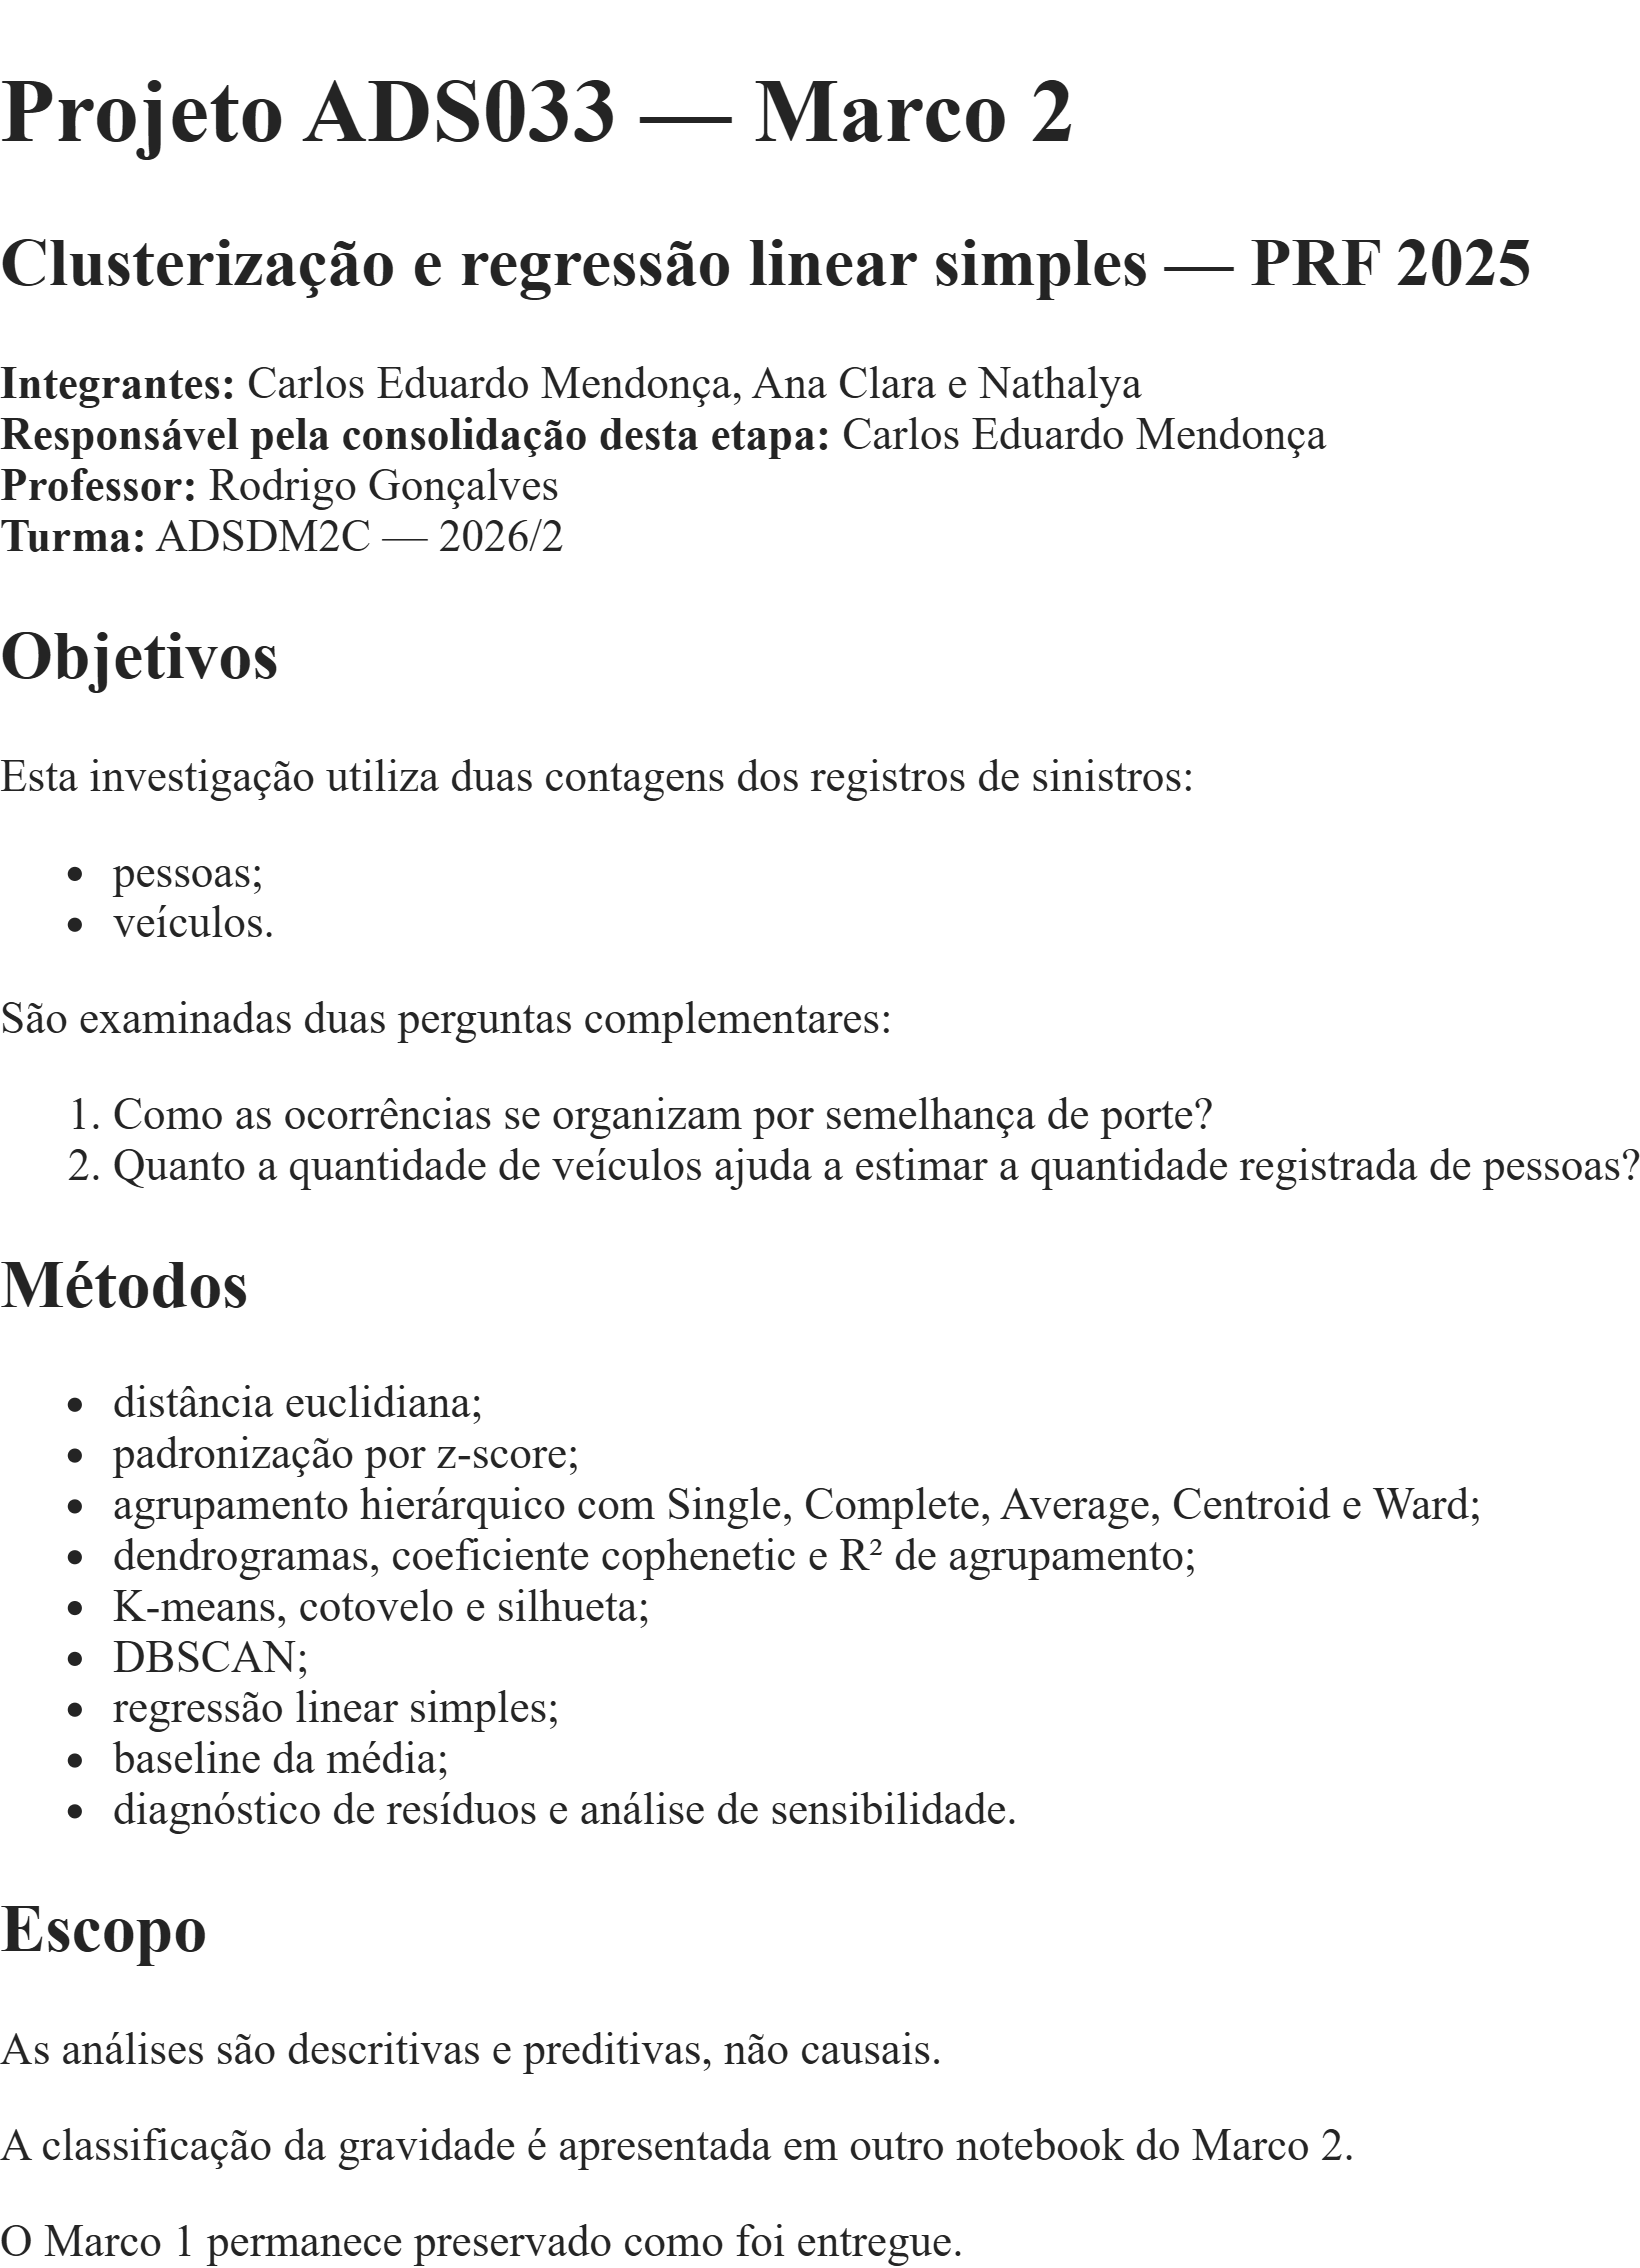

In [1]:
# Bibliotecas de sistema, cálculo e manipulação de dados.
import os
import numpy as np
import pandas as pd

# Gráficos e exibição de tabelas.
import matplotlib.pyplot as plt
from IPython.display import display

# Preparação e agrupamento.
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score

# Agrupamento hierárquico e distâncias.
from scipy.cluster.hierarchy import (
    linkage, dendrogram, cophenet, fcluster
)
from scipy.spatial.distance import pdist, squareform

# Regressão e avaliação.
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score
)
import statsmodels.api as sm

RANDOM_STATE = 42
ATRIBUTOS_CLUSTER = ["pessoas", "veiculos"]

pd.set_option("display.max_columns", None)

# Leitura da base no ambiente Colab.
from google.colab import drive
drive.mount("/content/drive", force_remount=False)

CAMINHO_BASE = (
    "/content/drive/MyDrive/base_compartilhada/datatran2025.csv"
)

if not os.path.isfile(CAMINHO_BASE):
    raise FileNotFoundError(CAMINHO_BASE)

df = pd.read_csv(
    CAMINHO_BASE,
    sep=";",
    decimal=",",
    encoding="latin1",
    low_memory=False
)

# Contrato da versão consolidada.
assert df.shape == (72_529, 30)
assert df["id"].notna().all() and df["id"].is_unique

COLUNAS_CONTAGEM = [
    "pessoas", "veiculos", "mortos", "feridos_graves",
    "feridos_leves", "feridos", "ilesos", "ignorados"
]

assert df[COLUNAS_CONTAGEM].notna().all().all()
assert np.isfinite(df[COLUNAS_CONTAGEM].to_numpy()).all()
assert df[ATRIBUTOS_CLUSTER].ge(1).all().all()

# O alvo não participa da formação dos grupos.
df["alvo_grave"] = (
    df["mortos"].gt(0) | df["feridos_graves"].gt(0)
).astype("int8")

# Reprodução da partição utilizada no projeto.
treino, teste = train_test_split(
    df,
    test_size=0.30,
    stratify=df["alvo_grave"],
    random_state=RANDOM_STATE
)

treino = treino.copy()
teste = teste.copy()

assert len(treino) == 50_770
assert len(teste) == 21_759
assert treino.index.intersection(teste.index).empty

# Auditoria contábil, sem correção ou exclusão automática.
treino["soma_categorias_pessoas"] = (
    treino["mortos"] + treino["feridos"]
    + treino["ilesos"] + treino["ignorados"]
)

treino["diferenca_contabil"] = (
    treino["pessoas"] - treino["soma_categorias_pessoas"]
)

treino["contagem_divergente"] = treino["diferenca_contabil"].ne(0)

display(pd.DataFrame({
    "particao": ["Treino", "Teste"],
    "ocorrencias": [len(treino), len(teste)]
}))

print(
    "Divergências contábeis no treino:",
    int(treino["contagem_divergente"].sum())
)

Mounted at /content/drive


,particao,ocorrencias
0,Treino,50770
1,Teste,21759


Divergências contábeis no treino: 2685


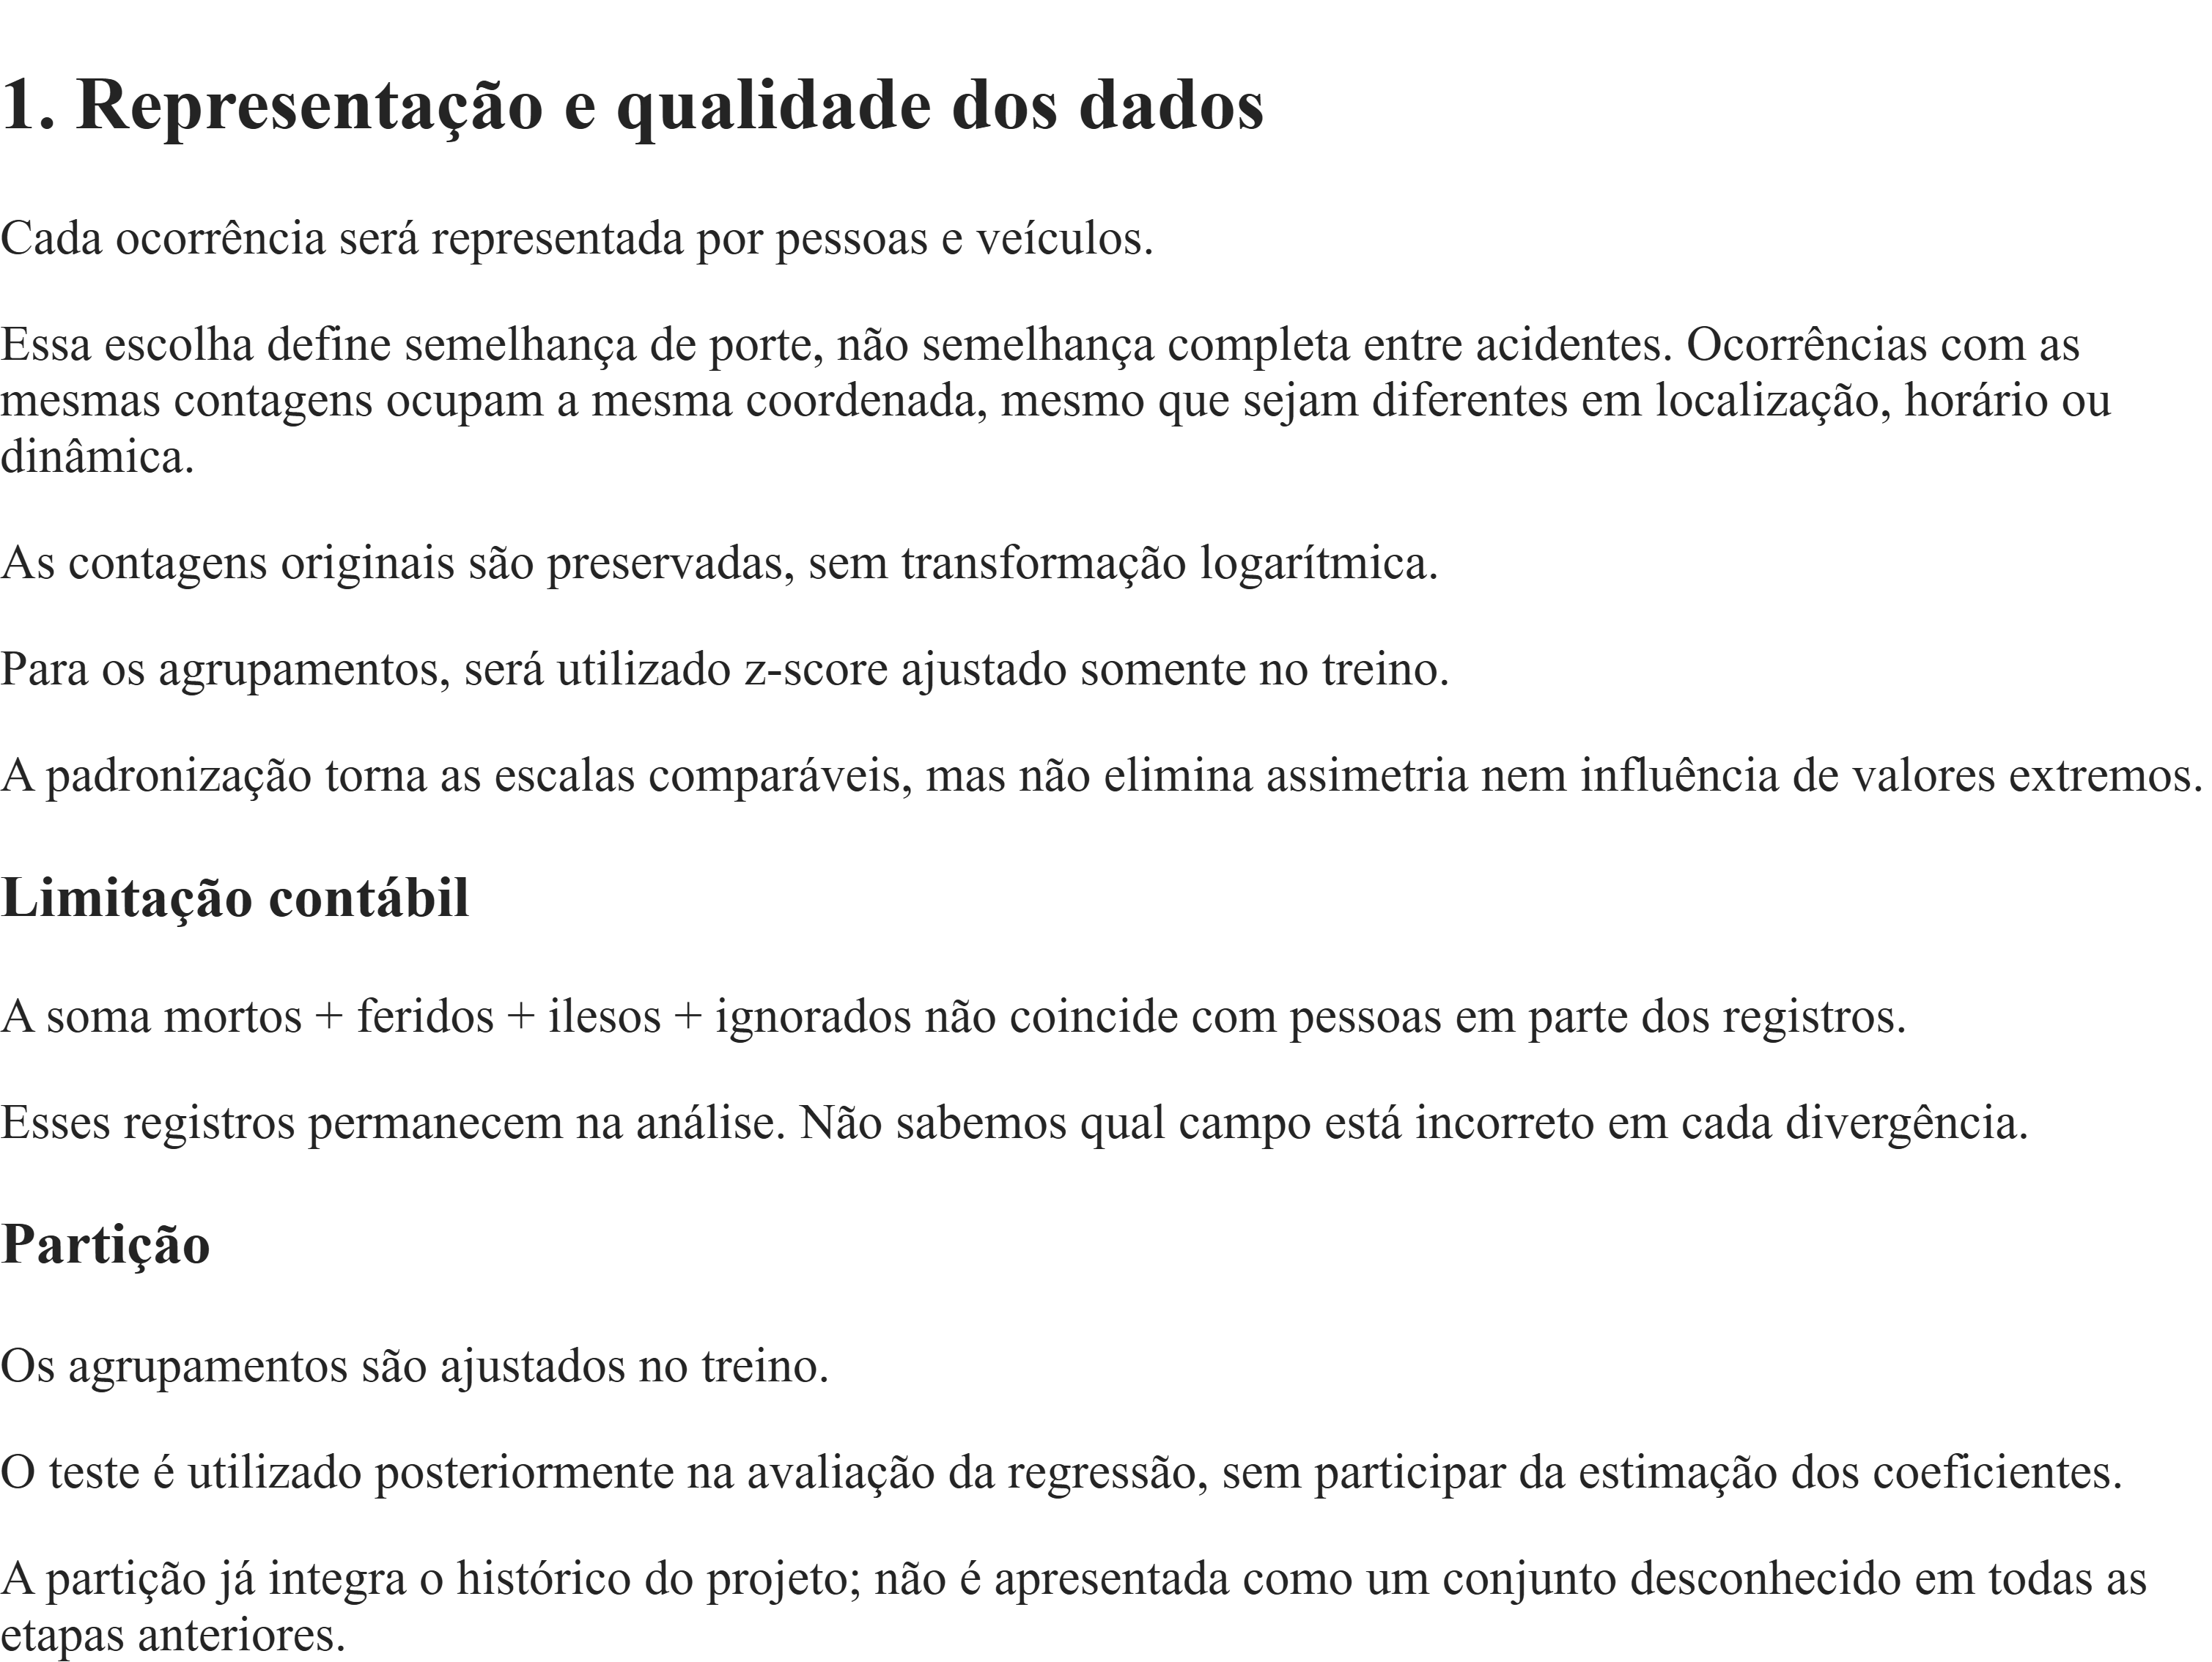

,minimo,q1,mediana,media,q3,maximo,DP_amostral,IQR
pessoas,1,2.0,2.0,2.594,3.0,76,2.275,1.0
veiculos,1,1.0,2.0,2.000,2.0,82,1.145,1.0


Distância manual: 1.4142135623730951
Distância pela biblioteca: 1.4142135623730951


,24835,34396,10610,49364,60777
24835,0.000,1.414,1.414,1.0,1.414
34396,1.414,0.000,0.000,1.0,0.000
10610,1.414,0.000,0.000,1.0,0.000
49364,1.000,1.000,1.000,0.0,1.000
60777,1.414,0.000,0.000,1.0,0.000


,media_aprendida,escala_aprendida,media_apos,DP_ddof0_apos
pessoas,2.59397,2.27498,-0.0,1.0
veiculos,1.99967,1.14509,-0.0,1.0


Representações repetidas: 50516
Percentual: 99.50%


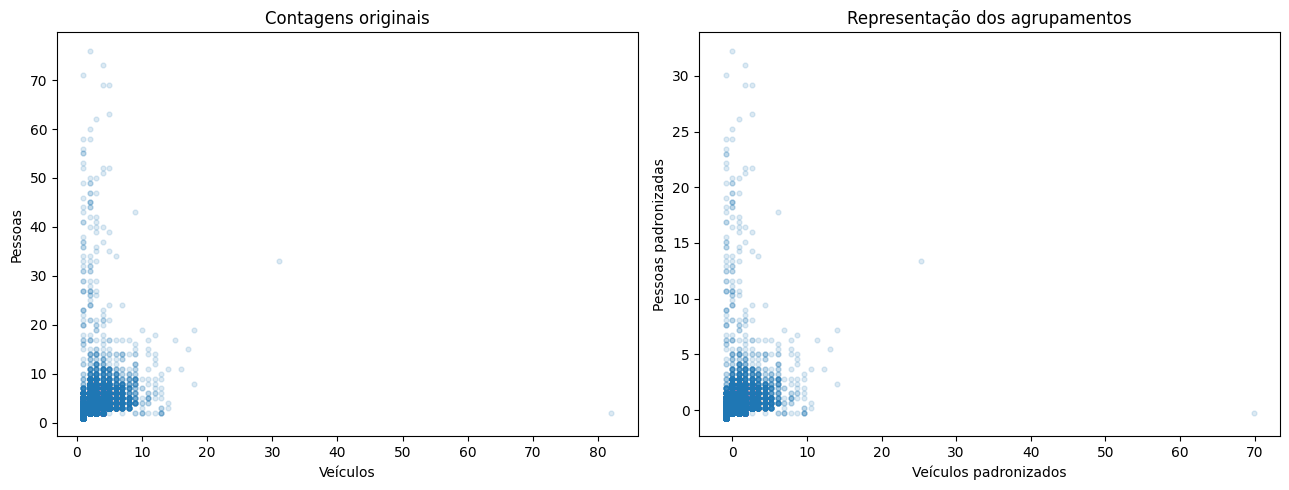

In [2]:
# Estatística descritiva das contagens.
resumo = pd.DataFrame({
    "minimo": treino[ATRIBUTOS_CLUSTER].min(),
    "q1": treino[ATRIBUTOS_CLUSTER].quantile(0.25),
    "mediana": treino[ATRIBUTOS_CLUSTER].median(),
    "media": treino[ATRIBUTOS_CLUSTER].mean(),
    "q3": treino[ATRIBUTOS_CLUSTER].quantile(0.75),
    "maximo": treino[ATRIBUTOS_CLUSTER].max(),
    "DP_amostral": treino[ATRIBUTOS_CLUSTER].std(ddof=1)
})

resumo["IQR"] = resumo["q3"] - resumo["q1"]
display(resumo.round(3))

# Demonstração e conferência da distância euclidiana.
exemplos = treino[ATRIBUTOS_CLUSTER].sample(
    5, random_state=RANDOM_STATE
)

diferencas = exemplos.iloc[0] - exemplos.iloc[1]
distancia_manual = np.sqrt(diferencas.pow(2).sum())
distancia_scipy = pdist(exemplos.iloc[:2].to_numpy())[0]

assert np.isclose(distancia_manual, distancia_scipy)

print("Distância manual:", distancia_manual)
print("Distância pela biblioteca:", distancia_scipy)

display(pd.DataFrame(
    squareform(pdist(exemplos.to_numpy())),
    index=exemplos.index,
    columns=exemplos.index
).round(3))

# Padronização ajustada exclusivamente no treino.
scaler = StandardScaler()
Z = scaler.fit_transform(treino[ATRIBUTOS_CLUSTER])

assert np.isfinite(Z).all()
assert treino[ATRIBUTOS_CLUSTER].std(ddof=0).gt(0).all()

display(pd.DataFrame({
    "media_aprendida": scaler.mean_,
    "escala_aprendida": scaler.scale_,
    "media_apos": Z.mean(axis=0),
    "DP_ddof0_apos": Z.std(axis=0, ddof=0)
}, index=ATRIBUTOS_CLUSTER).round(5))

# Pontos repetidos não significam IDs duplicados.
repetidos = int(pd.DataFrame(Z).duplicated().sum())

print("Representações repetidas:", repetidos)
print(f"Percentual: {repetidos / len(Z):.2%}")

# Visualização completa, com eixos lineares.
fig, eixos = plt.subplots(1, 2, figsize=(13, 5))

eixos[0].scatter(
    treino["veiculos"], treino["pessoas"], alpha=0.15, s=12
)
eixos[0].set_xlabel("Veículos")
eixos[0].set_ylabel("Pessoas")
eixos[0].set_title("Contagens originais")

eixos[1].scatter(Z[:, 1], Z[:, 0], alpha=0.15, s=12)
eixos[1].set_xlabel("Veículos padronizados")
eixos[1].set_ylabel("Pessoas padronizadas")
eixos[1].set_title("Representação dos agrupamentos")

plt.tight_layout()
plt.show()

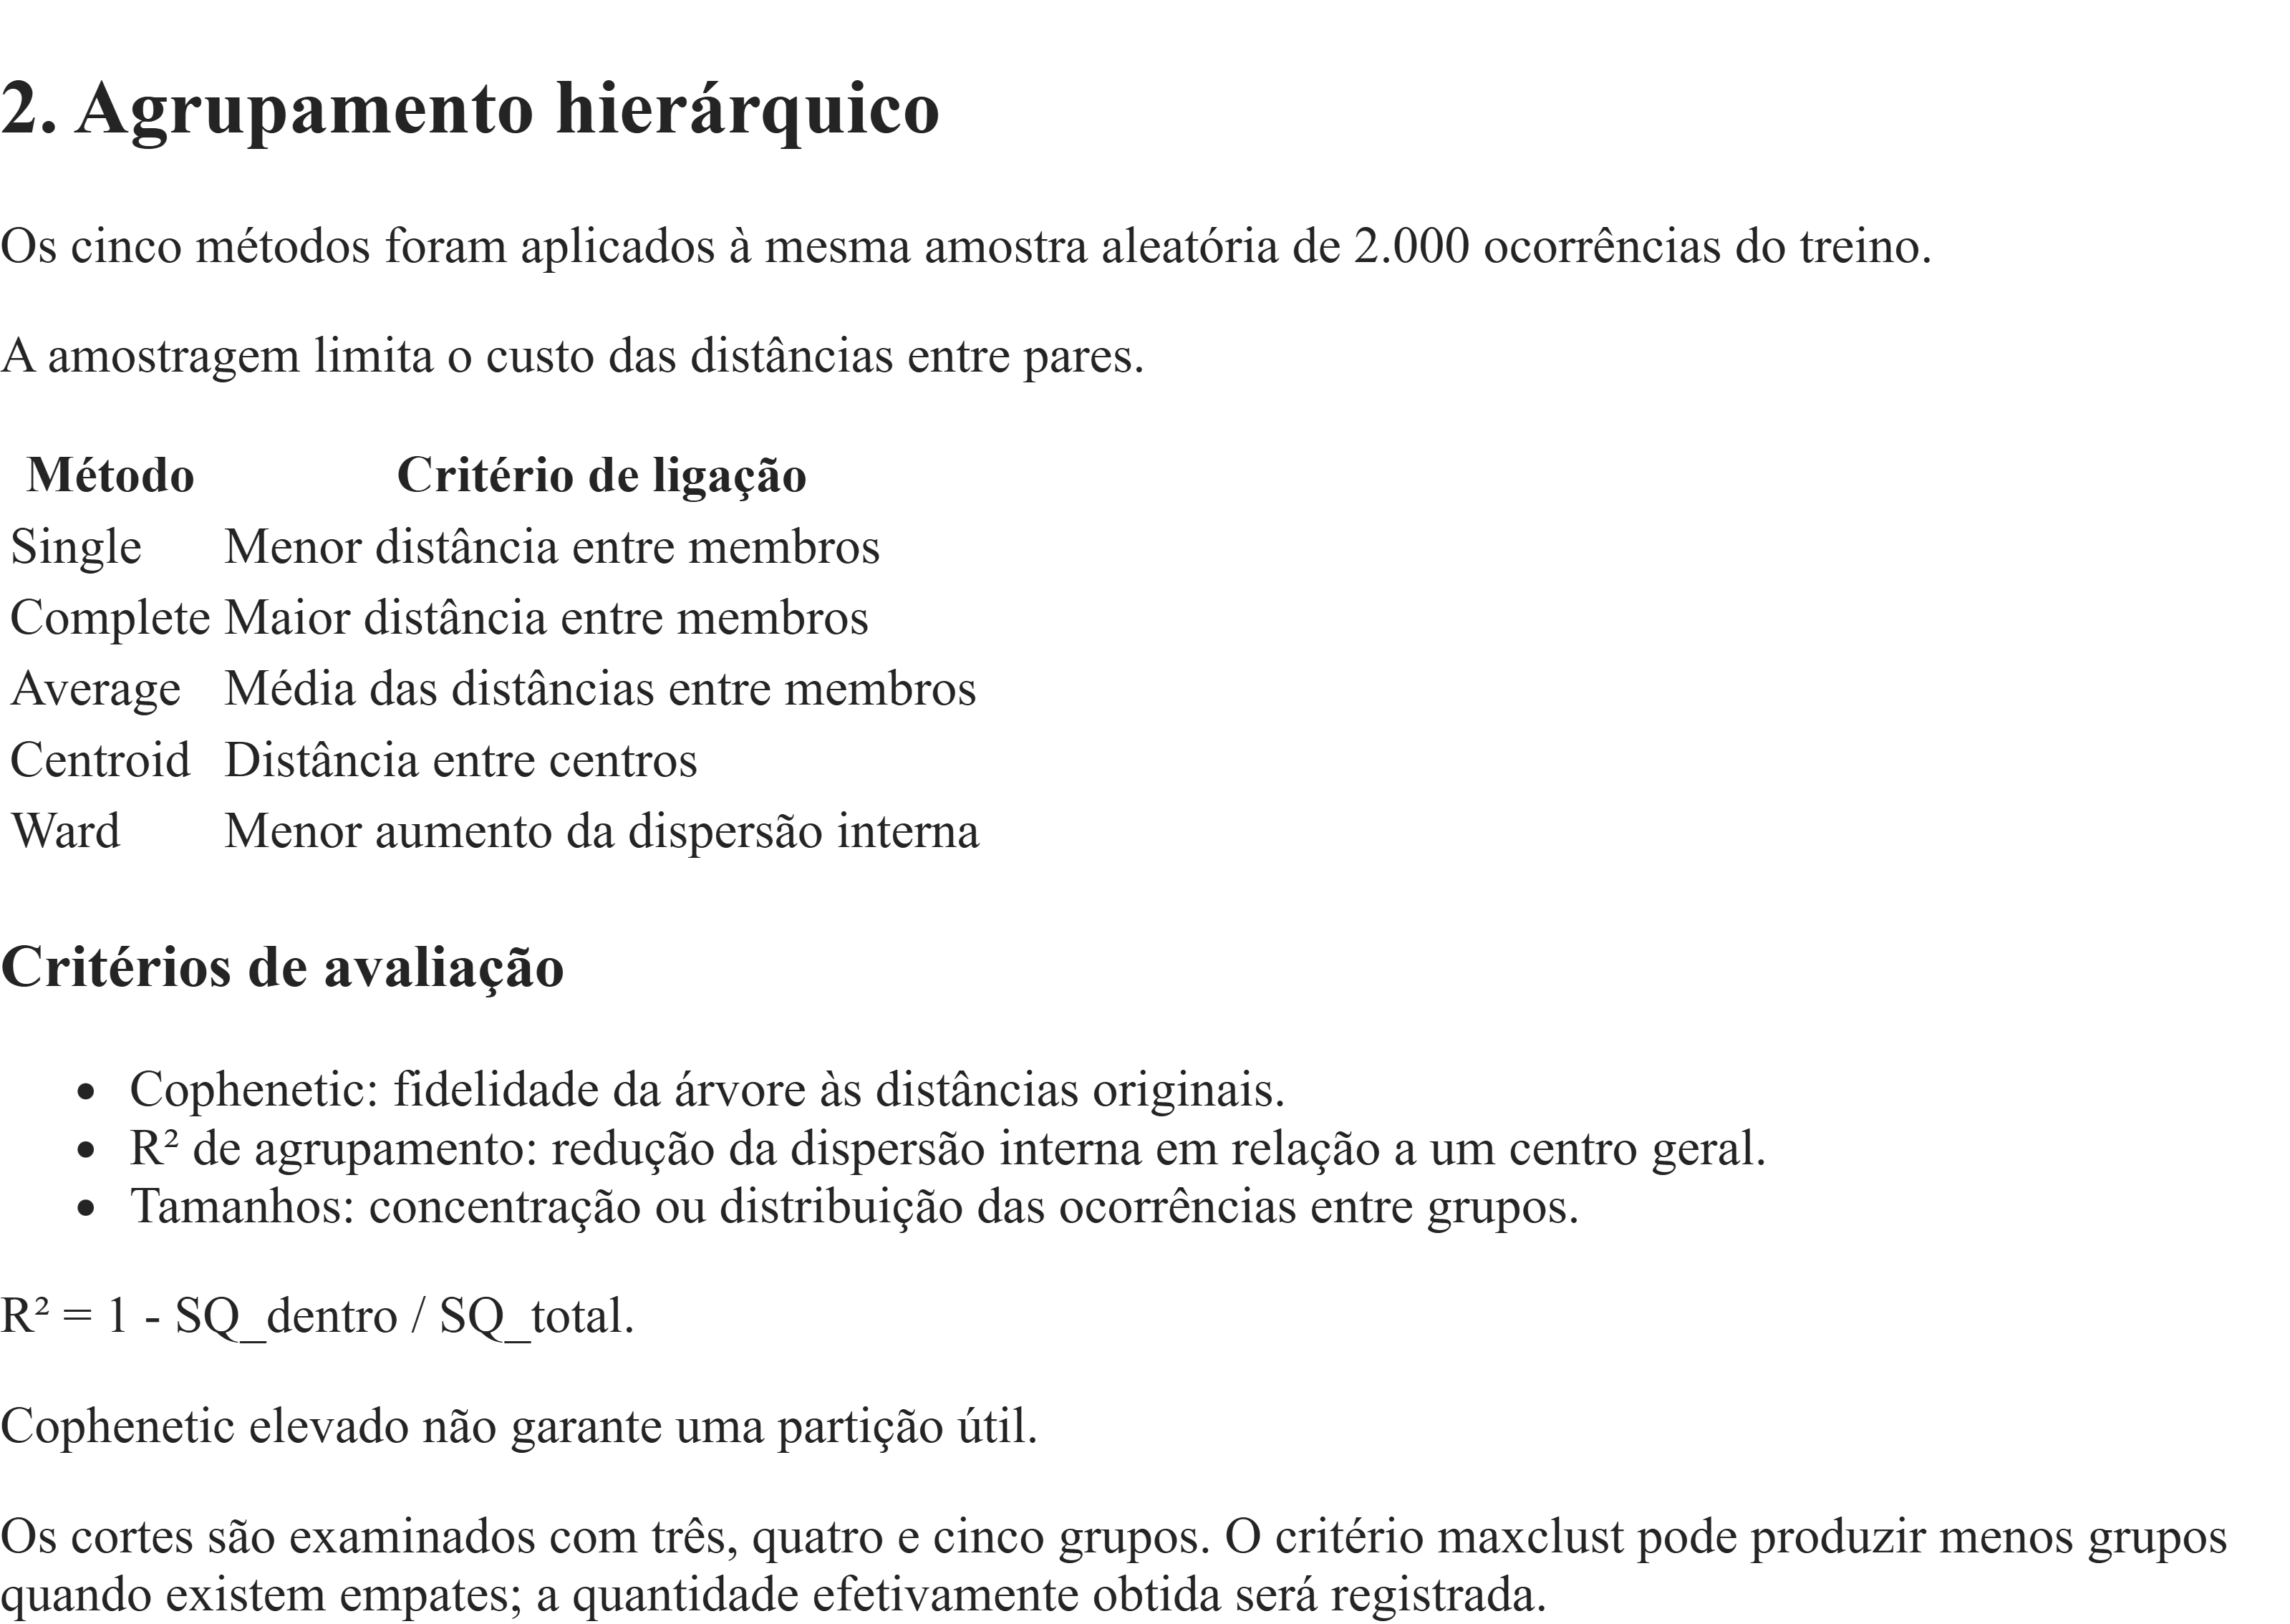

,metodo,cophenetic
3,centroid,0.9262
2,average,0.9242
1,complete,0.8864
0,single,0.7993
4,ward,0.5213


,metodo,k_solicitado,grupos_obtidos,R2,maior_grupo_pct,menor_grupo
0,single,3,3,0.160,99.90,1
1,single,4,4,0.184,99.85,1
2,single,5,5,0.367,99.60,1
3,complete,3,3,0.349,99.55,2
4,complete,4,4,0.368,99.55,1
5,complete,5,5,0.483,98.55,1
6,average,3,3,0.349,99.60,2
7,average,4,4,0.365,99.60,1
8,average,5,5,0.391,99.50,1
9,centroid,3,3,0.349,99.60,2


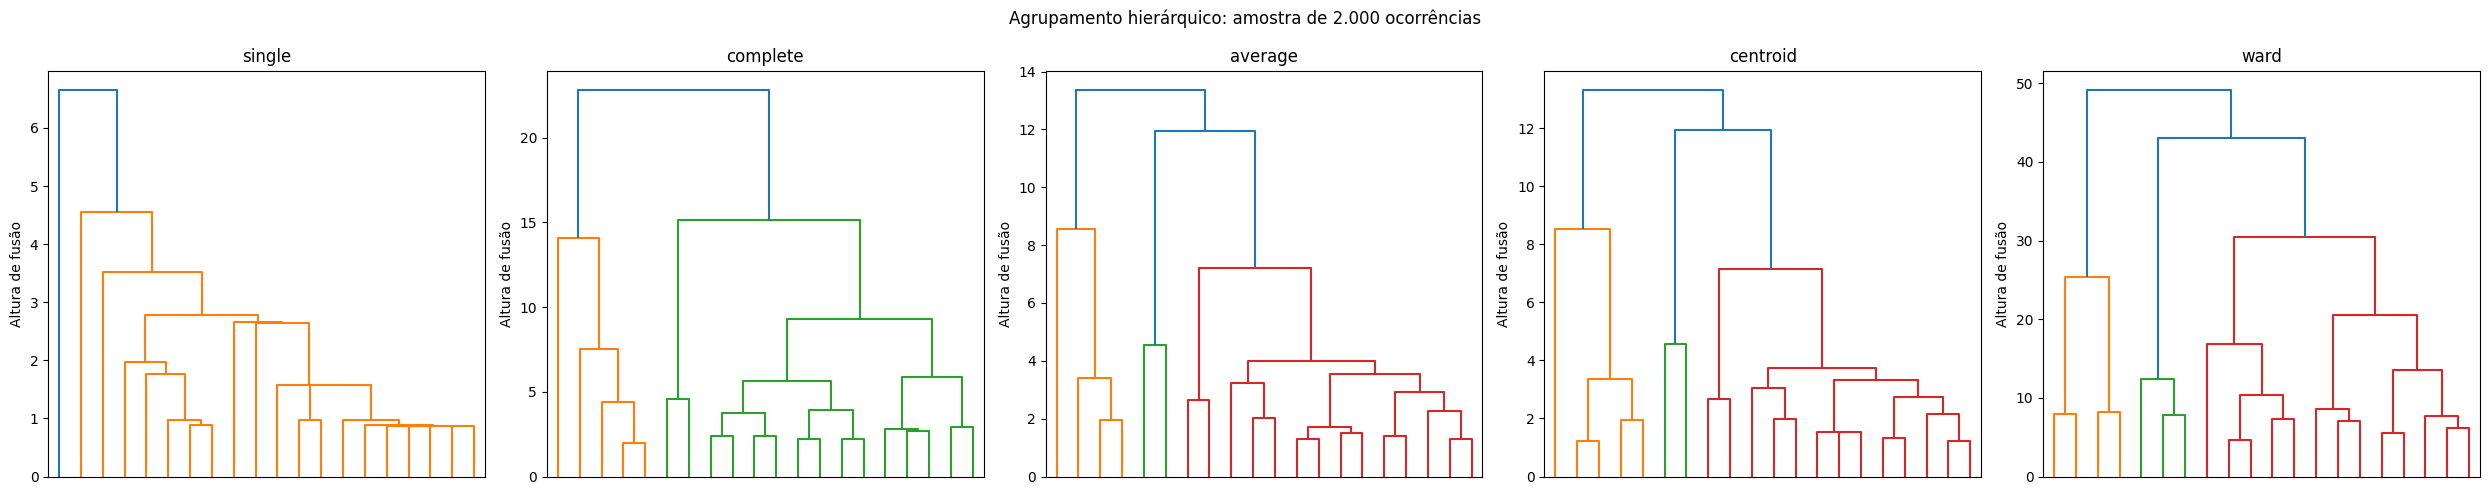

In [3]:
# Mesma amostra em todos os métodos.
indices_hier = np.random.default_rng(42).choice(
    len(Z), size=2_000, replace=False
)

Z_hier = Z[indices_hier]
distancias_hier = pdist(Z_hier)

METODOS = ["single", "complete", "average", "centroid", "ward"]

arvores = {}
coeficientes_cophenetic = []

for metodo in METODOS:
    arvore = linkage(Z_hier, method=metodo, metric="euclidean")
    arvores[metodo] = arvore

    coeficiente, _ = cophenet(arvore, distancias_hier)

    coeficientes_cophenetic.append({
        "metodo": metodo,
        "cophenetic": coeficiente
    })

tabela_cophenetic = pd.DataFrame(
    coeficientes_cophenetic
).sort_values("cophenetic", ascending=False)

display(tabela_cophenetic.round(4))


def r2_agrupamento(dados, rotulos):
    centros = (
        pd.DataFrame(dados)
        .groupby(rotulos)
        .transform("mean")
        .to_numpy()
    )

    sq_dentro = np.square(dados - centros).sum()
    sq_total = np.square(dados - dados.mean(axis=0)).sum()

    return np.nan if sq_total == 0 else 1 - sq_dentro / sq_total


resultados_cortes = []

for metodo in METODOS:
    for k in [3, 4, 5]:
        rotulos = fcluster(
            arvores[metodo], t=k, criterion="maxclust"
        )

        tamanhos = pd.Series(rotulos).value_counts()

        resultados_cortes.append({
            "metodo": metodo,
            "k_solicitado": k,
            "grupos_obtidos": len(tamanhos),
            "R2": r2_agrupamento(Z_hier, rotulos),
            "maior_grupo_pct": tamanhos.max() / len(rotulos) * 100,
            "menor_grupo": tamanhos.min()
        })

tabela_cortes = pd.DataFrame(resultados_cortes)
display(tabela_cortes.round(3))

# Dendrogramas truncados para legibilidade.
fig, eixos = plt.subplots(1, 5, figsize=(25, 5))

for eixo, metodo in zip(eixos, METODOS):
    dendrogram(
        arvores[metodo],
        truncate_mode="lastp",
        p=20,
        no_labels=True,
        ax=eixo
    )
    eixo.set_title(metodo)
    eixo.set_ylabel("Altura de fusão")

plt.suptitle("Agrupamento hierárquico: amostra de 2.000 ocorrências")
plt.tight_layout()
plt.show()

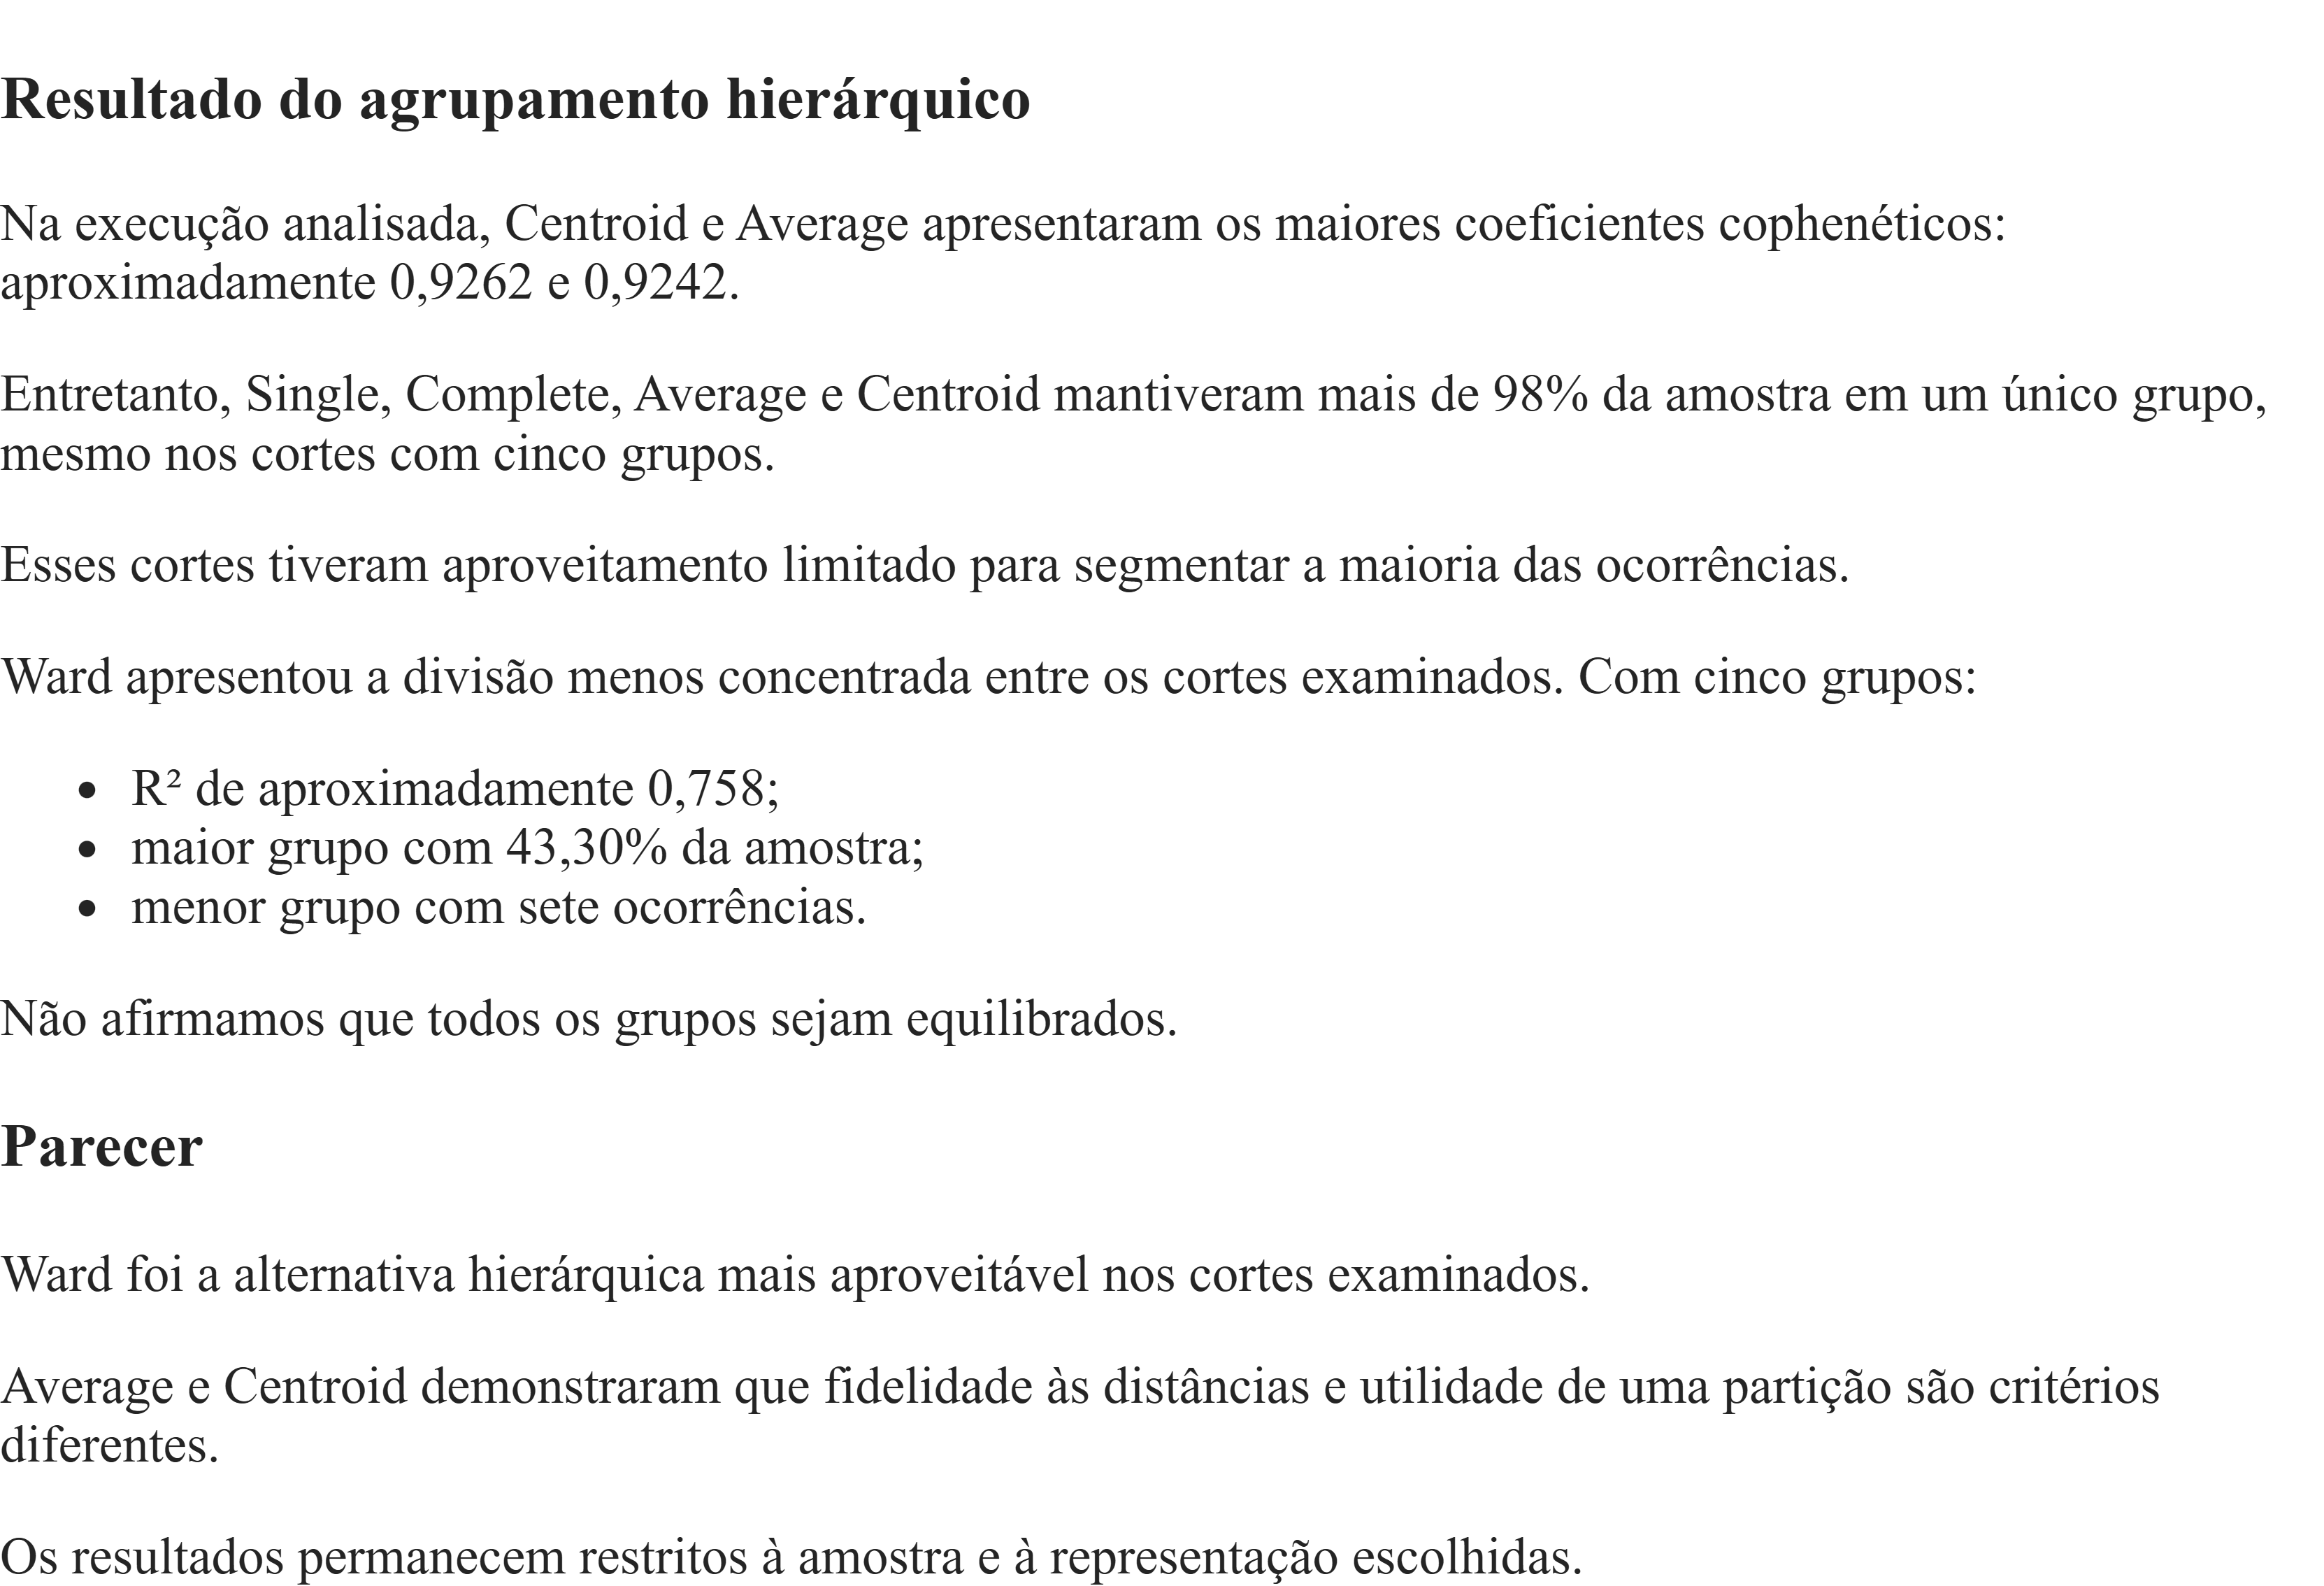

## 3. K-means: escolha da quantidade de grupos

Foram examinadas soluções de um a dez grupos na mesma representação padronizada de pessoas e veículos.

A comparação utilizou:

- inércia e gráfico do cotovelo;
- silhueta na mesma amostra de 2.000 ocorrências;
- tamanhos dos grupos;
- interpretação das contagens originais.

### Evidência quantitativa

A solução com dois grupos apresentou:

- silhueta de aproximadamente 0,5877;
- menor grupo com 22,35% das ocorrências;
- maior grupo com 77,65%.

A solução com dez grupos apresentou silhueta maior, aproximadamente 0,6963, mas incluiu grupos muito pequenos e uma ocorrência isolada.

O cotovelo não indicou inequivocamente dois grupos. A inércia continuou diminuindo com o aumento de k.

Portanto, dois grupos não foram escolhidos por maximizar a silhueta nem por um cotovelo inequívoco.

### Evidência descritiva no domínio

A solução com dois grupos produziu uma síntese compreensível de porte:

| Perfil | Mediana de pessoas | Mediana de veículos |
|---|---:|---:|
| Menor porte | 2 | 2 |
| Maior porte | 4 | 3 |

Os dois grupos possuem participação relevante na amostra de treino.

A interpretação distingue portes gerais sem depender de grupos com apenas uma ocorrência ou poucas dezenas de registros.

Essa evidência descritiva complementa a avaliação quantitativa. Não constitui uma validação estatística independente da representação.

### Decisão

A solução com dois grupos foi adotada como síntese descritiva principal.

A solução com dez grupos foi preservada como detalhamento complementar, incluindo a separação de combinações raras e ocorrências extremas.

A escolha é orientada pela finalidade da investigação. Não demonstra a existência de dois tipos naturais de acidente.

### Limites dos critérios

Inércia e R² não são evidências independentes: o R² de agrupamento é calculado a partir da dispersão interna.

Silhueta e cotovelo são critérios complementares, mas ambos dependem da representação e das distâncias escolhidas.

A sensibilidade ao registro extremo avalia a estabilidade da solução de dois grupos perante esse registro específico. Ela não determina, isoladamente, a melhor quantidade de grupos.

A proporção de graves não foi utilizada para escolher k.
)

,k,inercia,R2,silhueta_amostra,menor_grupo_pct,maior_grupo_pct
0,1,101540.0000,0.0000,NaN,100.0000,100.0000
1,2,66405.4555,0.3460,0.5877,22.3538,77.6462
2,3,43858.5600,0.5681,0.5952,0.1851,79.2633
3,4,32577.7294,0.6792,0.5662,0.1851,60.5870
4,5,25836.8728,0.7455,0.6151,0.1851,47.4867
5,6,21417.9846,0.7891,0.6151,0.0020,47.4867
6,7,17361.7712,0.8290,0.6526,0.0020,46.6220
7,8,14738.8943,0.8548,0.6824,0.0020,42.1725
8,9,12396.6313,0.8779,0.6632,0.0020,46.2104
9,10,10460.2998,0.8970,0.6963,0.0020,42.1725


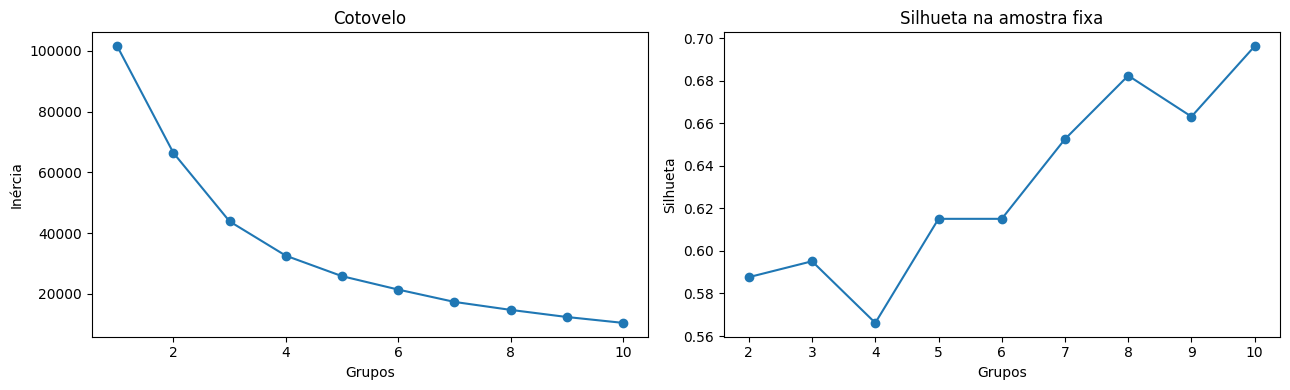

,ocorrencias,pessoas_media,pessoas_mediana,pessoas_q3,pessoas_maximo,veiculos_media,veiculos_mediana,veiculos_q3,veiculos_maximo,divergencias_pct,participacao_pct
grupo_porte,,,,,,,,,,,
0,39421,2.009,2.0,2.0,7,1.582,2.0,2.0,2,0.000,77.646
1,11349,4.625,4.0,5.0,76,3.451,3.0,4.0,82,23.658,22.354


,pessoas,veiculos
grupo_porte,,
0,2.0094,1.5817
1,4.6245,3.4513


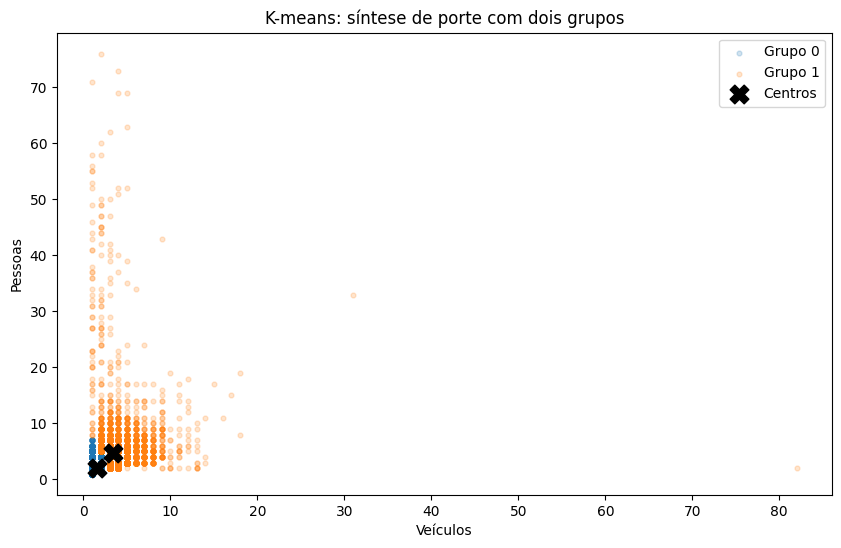

,ocorrencias,graves,graves_pct
grupo_porte,,,
0,39421,10287,26.095
1,11349,4058,35.756


In [4]:
# Amostra fixa de avaliação.
indices_avaliacao = np.random.default_rng(42).choice(
    len(Z), size=2_000, replace=False
)

Z_avaliacao = Z[indices_avaliacao]
sq_total = np.square(Z - Z.mean(axis=0)).sum()

modelos_k = {}
resultados_k = []

for k in range(1, 11):
    modelo = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    ).fit(Z)

    modelos_k[k] = modelo

    rotulos_amostra = modelo.labels_[indices_avaliacao]
    quantidade_grupos = np.unique(rotulos_amostra).size

    silhueta = np.nan

    if 2 <= quantidade_grupos < len(Z_avaliacao):
        silhueta = silhouette_score(
            Z_avaliacao, rotulos_amostra
        )

    tamanhos = pd.Series(modelo.labels_).value_counts()

    resultados_k.append({
        "k": k,
        "inercia": modelo.inertia_,
        "R2": 1 - modelo.inertia_ / sq_total,
        "silhueta_amostra": silhueta,
        "menor_grupo_pct": tamanhos.min() / len(Z) * 100,
        "maior_grupo_pct": tamanhos.max() / len(Z) * 100
    })

tabela_k = pd.DataFrame(resultados_k)
display(tabela_k.round(4))

fig, eixos = plt.subplots(1, 2, figsize=(13, 4))

eixos[0].plot(tabela_k["k"], tabela_k["inercia"], marker="o")
eixos[0].set_title("Cotovelo")
eixos[0].set_xlabel("Grupos")
eixos[0].set_ylabel("Inércia")

eixos[1].plot(
    tabela_k["k"], tabela_k["silhueta_amostra"], marker="o"
)
eixos[1].set_title("Silhueta na amostra fixa")
eixos[1].set_xlabel("Grupos")
eixos[1].set_ylabel("Silhueta")

plt.tight_layout()
plt.show()

# Decisão congelada após a investigação anterior.
K_PRINCIPAL = 2
modelo_principal = modelos_k[K_PRINCIPAL]
treino["grupo_porte"] = modelo_principal.labels_

perfil = treino.groupby("grupo_porte").agg(
    ocorrencias=("id", "size"),
    pessoas_media=("pessoas", "mean"),
    pessoas_mediana=("pessoas", "median"),
    pessoas_q3=("pessoas", lambda s: s.quantile(0.75)),
    pessoas_maximo=("pessoas", "max"),
    veiculos_media=("veiculos", "mean"),
    veiculos_mediana=("veiculos", "median"),
    veiculos_q3=("veiculos", lambda s: s.quantile(0.75)),
    veiculos_maximo=("veiculos", "max"),
    divergencias_pct=("contagem_divergente", "mean")
)

perfil["participacao_pct"] = (
    perfil["ocorrencias"] / len(treino) * 100
)
perfil["divergencias_pct"] *= 100

display(perfil.round(3))

centros = scaler.inverse_transform(
    modelo_principal.cluster_centers_
)

display(pd.DataFrame(
    centros,
    columns=ATRIBUTOS_CLUSTER
).rename_axis("grupo_porte").round(4))

# Visualização nas unidades originais.
plt.figure(figsize=(10, 6))

for grupo in sorted(treino["grupo_porte"].unique()):
    dados_grupo = treino.loc[treino["grupo_porte"].eq(grupo)]

    plt.scatter(
        dados_grupo["veiculos"],
        dados_grupo["pessoas"],
        alpha=0.2,
        s=12,
        label=f"Grupo {grupo}"
    )

plt.scatter(
    centros[:, 1],
    centros[:, 0],
    color="black",
    marker="X",
    s=180,
    label="Centros"
)

plt.xlabel("Veículos")
plt.ylabel("Pessoas")
plt.title("K-means: síntese de porte com dois grupos")
plt.legend()
plt.show()

# Gravidade somente após a formação dos grupos.
gravidade = treino.groupby("grupo_porte").agg(
    ocorrencias=("id", "size"),
    graves=("alvo_grave", "sum")
)

gravidade["graves_pct"] = (
    gravidade["graves"] / gravidade["ocorrencias"] * 100
)

display(gravidade.round(3))

In [5]:
# Documenta a solução complementar sem alterar a solução principal.
detalhamento_k10 = treino[["id", "pessoas", "veiculos"]].copy()

# Recupera os rótulos do modelo já ajustado.
detalhamento_k10["grupo_k10"] = modelos_k[10].labels_

# Resume os tamanhos e as contagens de cada grupo.
perfil_k10 = detalhamento_k10.groupby("grupo_k10").agg(
    ocorrencias=("id", "size"),
    pessoas_mediana=("pessoas", "median"),
    pessoas_maximo=("pessoas", "max"),
    veiculos_mediana=("veiculos", "median"),
    veiculos_maximo=("veiculos", "max")
)

# Calcula a participação de cada grupo.
perfil_k10["participacao_pct"] = (
    perfil_k10["ocorrencias"].div(len(treino)).mul(100)
)

# Exibe a evidência do detalhamento e dos grupos pequenos.
display(perfil_k10.round(3))

,ocorrencias,pessoas_mediana,pessoas_maximo,veiculos_mediana,veiculos_maximo,participacao_pct
grupo_k10,,,,,,
0,21411,2.0,3,2.0,2,42.173
1,46,48.0,76,2.0,9,0.091
2,1358,4.0,13,5.0,8,2.675
3,3729,4.0,10,2.0,2,7.345
4,15694,1.0,3,1.0,1,30.912
5,149,7.0,33,9.0,31,0.293
6,6462,3.0,4,3.0,4,12.728
7,1,2.0,2,82.0,82,0.002
8,79,24.0,37,2.0,7,0.156


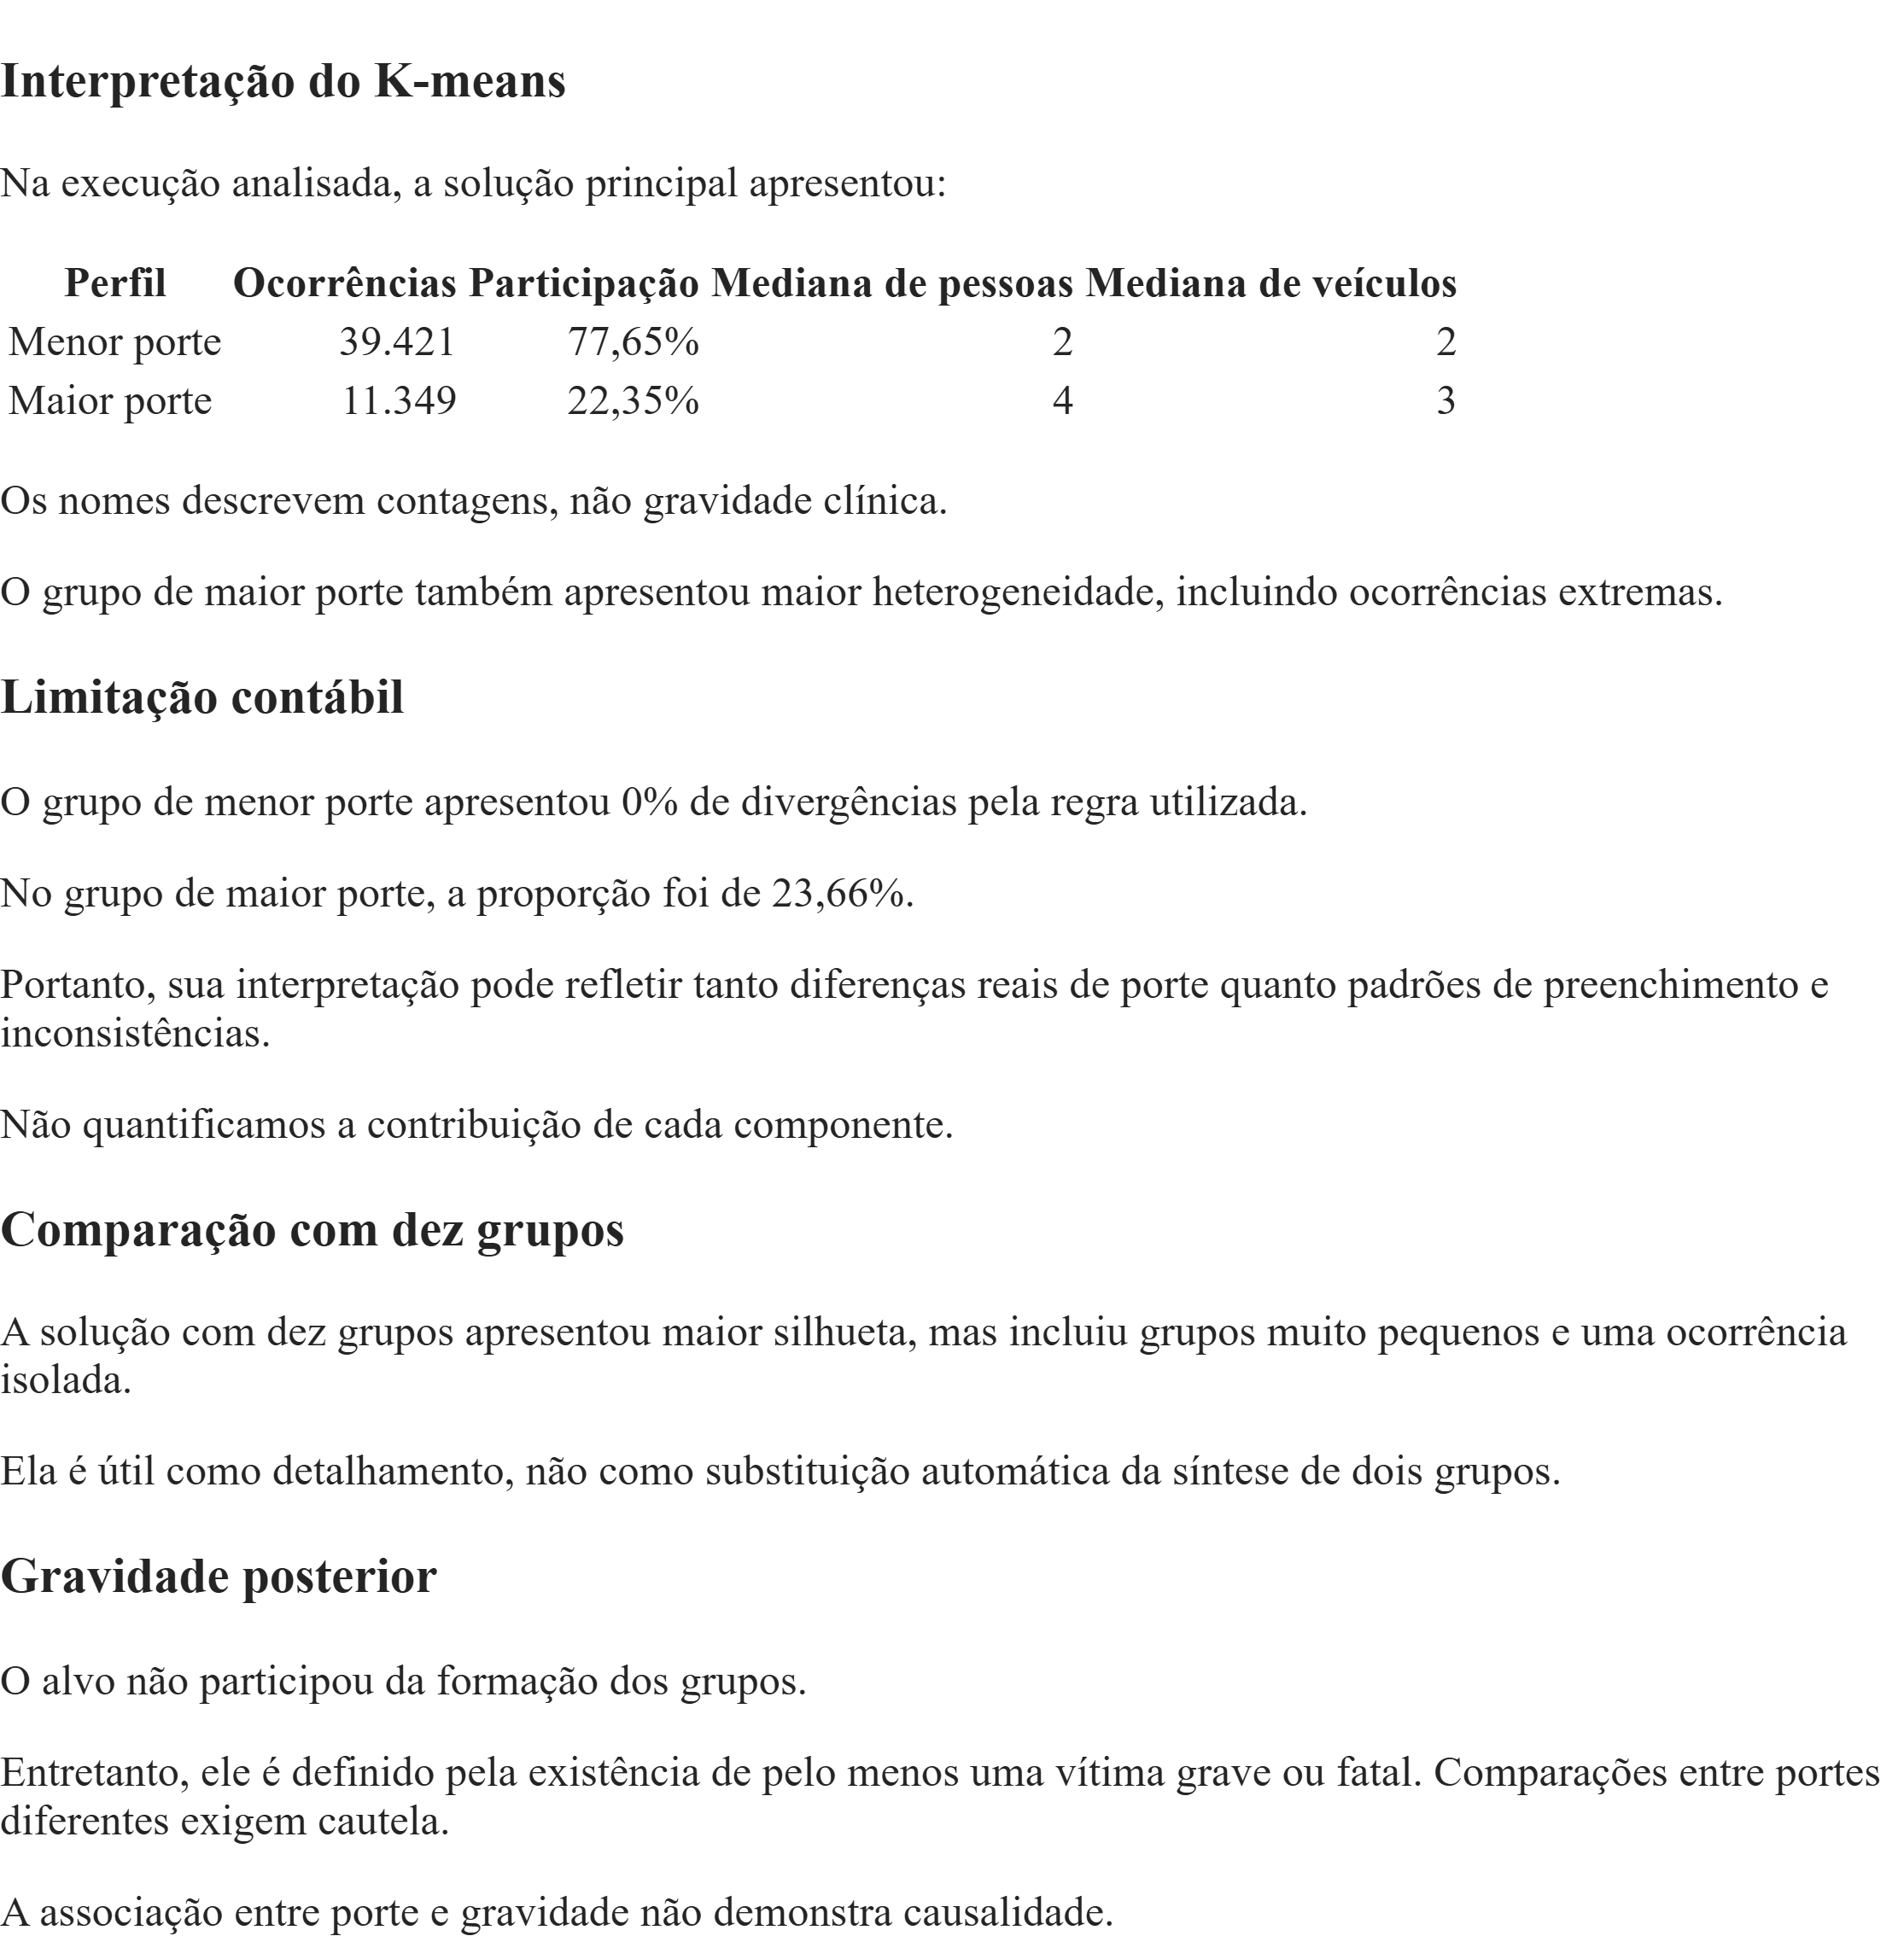

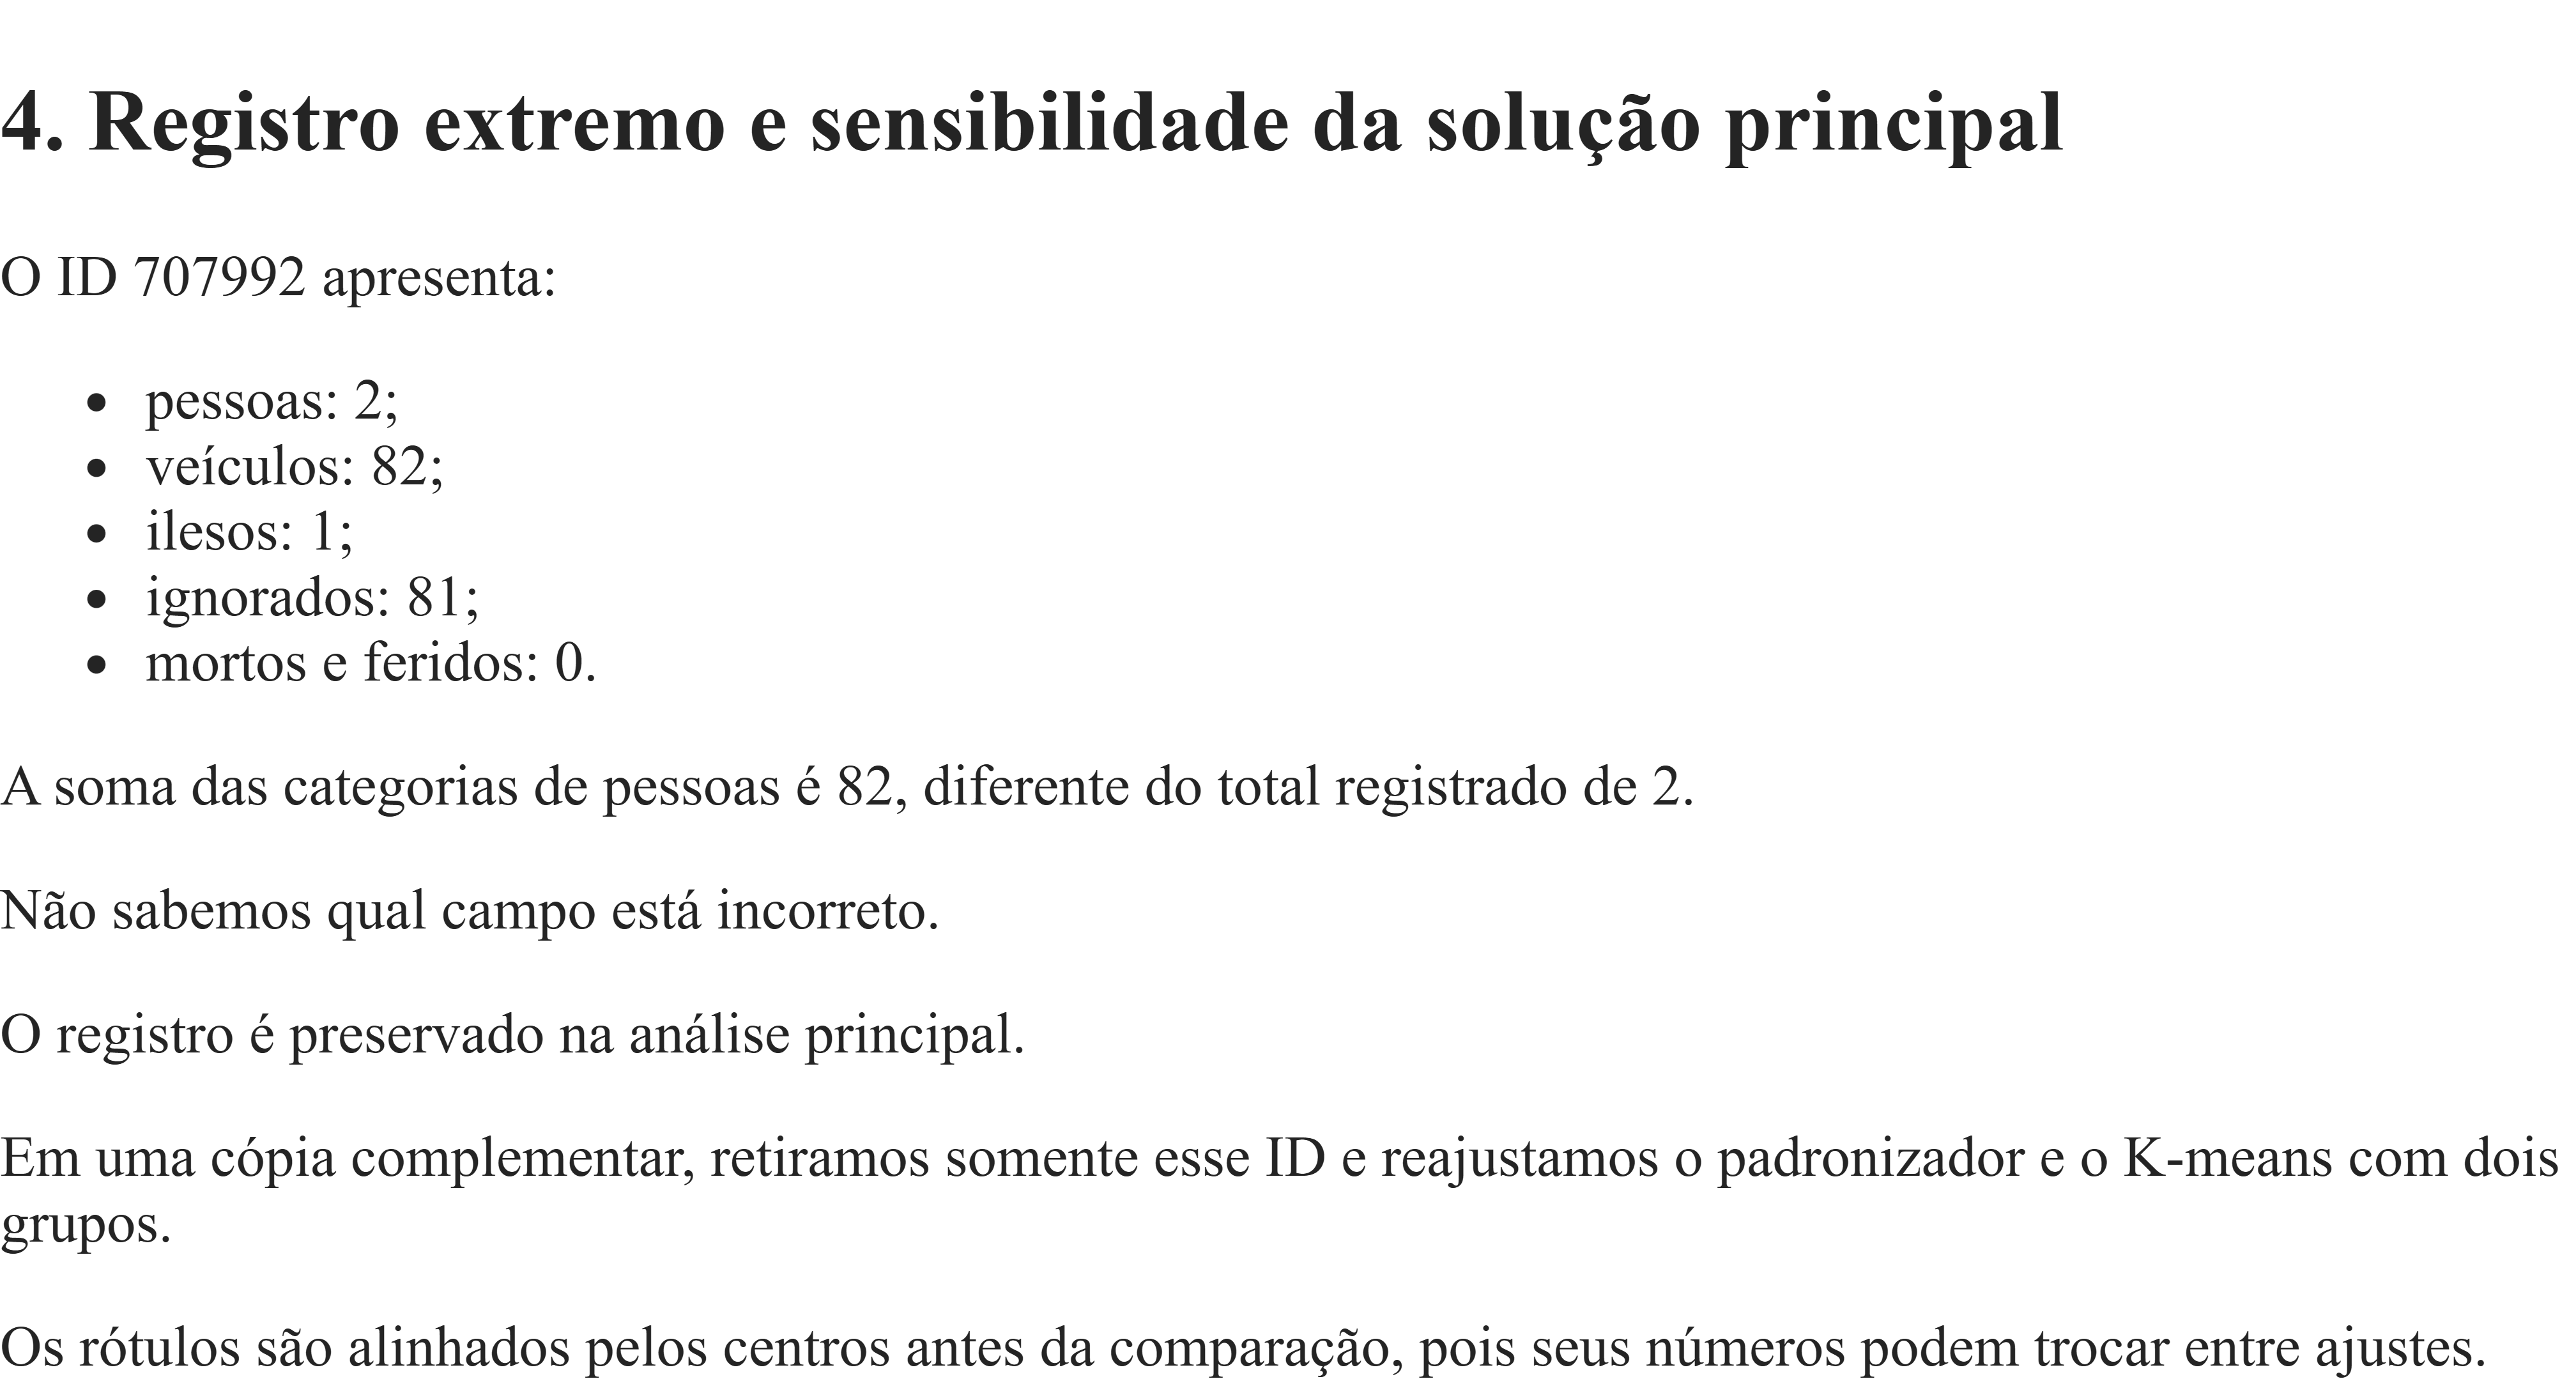

In [6]:
# Auditoria do registro.
caso_extremo = treino.loc[treino["id"].eq(707992)].copy()
assert len(caso_extremo) == 1

display(caso_extremo[[
    "id", "data_inversa", "uf", "municipio",
    "tipo_acidente", "pessoas", "veiculos",
    "mortos", "feridos", "ilesos", "ignorados",
    "soma_categorias_pessoas", "diferenca_contabil"
]].T)

# Experimento complementar sem alterar a base principal.
mascara_comuns = treino["id"].ne(707992)
treino_sem_extremo = treino.loc[mascara_comuns].copy()

scaler_sem_extremo = StandardScaler()
Z_sem_extremo = scaler_sem_extremo.fit_transform(
    treino_sem_extremo[ATRIBUTOS_CLUSTER]
)

modelo_sem_extremo = KMeans(
    n_clusters=2,
    n_init=10,
    random_state=42
).fit(Z_sem_extremo)

centros_sem = scaler_sem_extremo.inverse_transform(
    modelo_sem_extremo.cluster_centers_
)

custo_direto = np.square(centros - centros_sem).sum()
custo_invertido = np.square(centros - centros_sem[::-1]).sum()

inverter = custo_invertido < custo_direto

centros_alinhados = centros_sem[::-1] if inverter else centros_sem

rotulos_alinhados = (
    1 - modelo_sem_extremo.labels_
    if inverter
    else modelo_sem_extremo.labels_
)

rotulos_originais_comuns = modelo_principal.labels_[
    mascara_comuns.to_numpy()
]

mudancas = int(
    np.not_equal(
        rotulos_originais_comuns,
        rotulos_alinhados
    ).sum()
)

display(pd.DataFrame({
    "pessoas_com": centros[:, 0],
    "pessoas_sem": centros_alinhados[:, 0],
    "veiculos_com": centros[:, 1],
    "veiculos_sem": centros_alinhados[:, 1]
}).round(4))

print("Ocorrências comuns:", len(treino_sem_extremo))
print("Mudanças de grupo:", mudancas)
print(f"Percentual: {mudancas / len(treino_sem_extremo) * 100:.4f}%")

assert treino["id"].eq(707992).sum() == 1

,10260
id,707992
data_inversa,2025-07-07
uf,GO
municipio,PADRE BERNARDO
tipo_acidente,Incêndio
pessoas,2
veiculos,82
mortos,0
feridos,0
ilesos,1


,pessoas_com,pessoas_sem,veiculos_com,veiculos_sem
0,2.0094,2.0098,1.5817,1.5817
1,4.6245,4.6239,3.4513,3.4450


Ocorrências comuns: 50769
Mudanças de grupo: 3
Percentual: 0.0059%


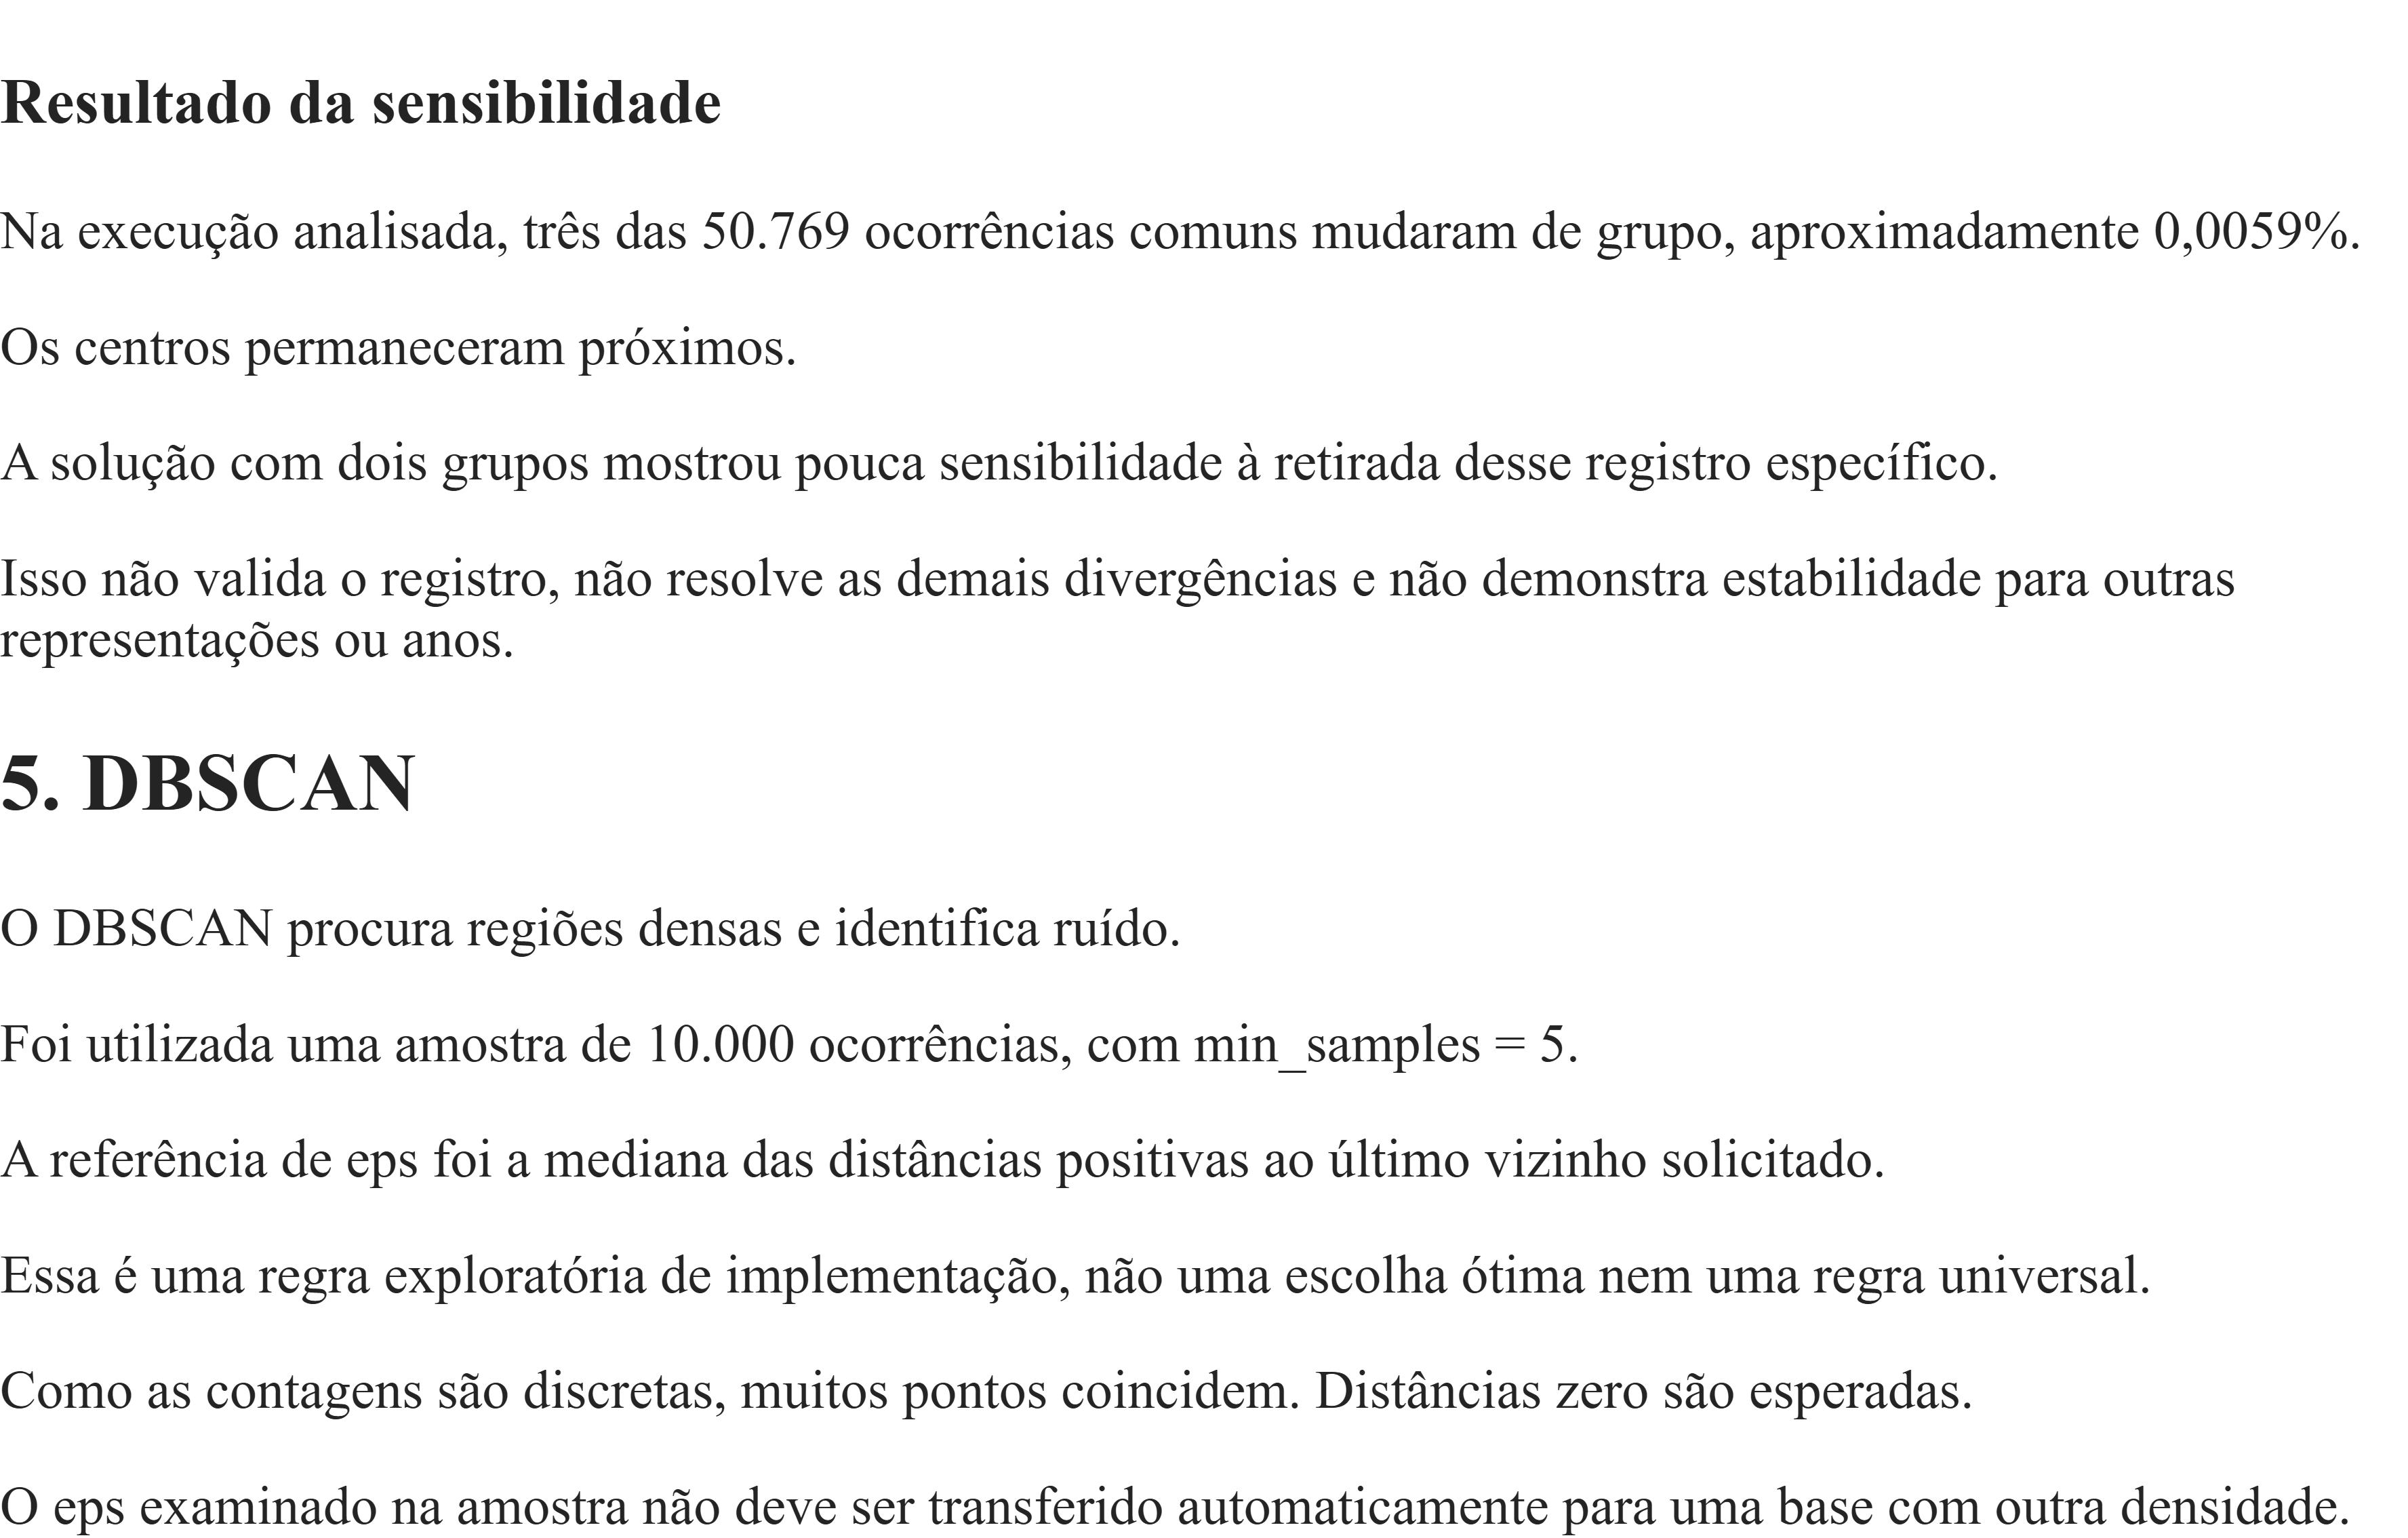

Distância zero ao último vizinho solicitado (%): 98.85


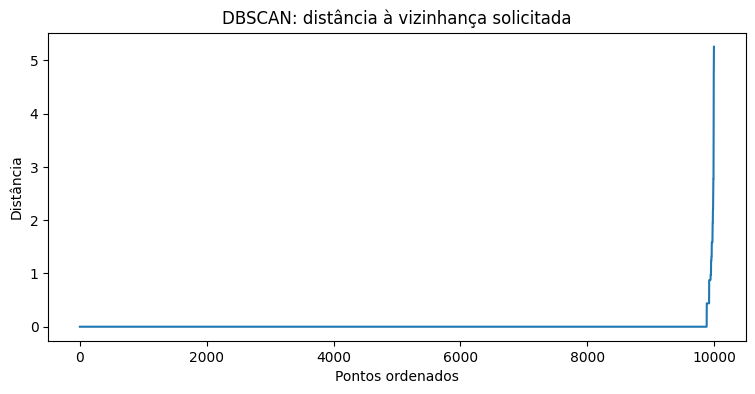

,eps,grupos,ruido_pct,maior_grupo
0,0.4396,23,0.87,3196
1,0.8791,1,0.49,9951
2,1.3187,4,0.22,9963
3,1.7583,5,0.12,9965


In [7]:
# Amostra reproduzível do DBSCAN.
indices_db = np.random.default_rng(42).choice(
    len(Z), size=10_000, replace=False
)
Z_db = Z[indices_db]

MIN_SAMPLES = 5

busca = NearestNeighbors(
    n_neighbors=MIN_SAMPLES
).fit(Z_db)

distancias, _ = busca.kneighbors(Z_db)
distancia_k = distancias[:, -1]

print(
    "Distância zero ao último vizinho solicitado (%):",
    round(np.mean(distancia_k == 0) * 100, 2)
)

plt.figure(figsize=(9, 4))
plt.plot(np.sort(distancia_k))
plt.xlabel("Pontos ordenados")
plt.ylabel("Distância")
plt.title("DBSCAN: distância à vizinhança solicitada")
plt.show()

positivas = distancia_k[distancia_k > 0]
assert len(positivas) > 0

EPS_REFERENCIA = float(np.median(positivas))
resultados_db = []

for fator in [0.5, 1.0, 1.5, 2.0]:
    eps = EPS_REFERENCIA * fator

    rotulos = DBSCAN(
        eps=eps,
        min_samples=MIN_SAMPLES
    ).fit_predict(Z_db)

    tamanhos = pd.Series(
        rotulos[rotulos >= 0]
    ).value_counts()

    resultados_db.append({
        "eps": eps,
        "grupos": len(tamanhos),
        "ruido_pct": np.mean(rotulos == -1) * 100,
        "maior_grupo": (
            int(tamanhos.max()) if not tamanhos.empty else 0
        )
    })

tabela_dbscan = pd.DataFrame(resultados_db)
display(tabela_dbscan.round(4))

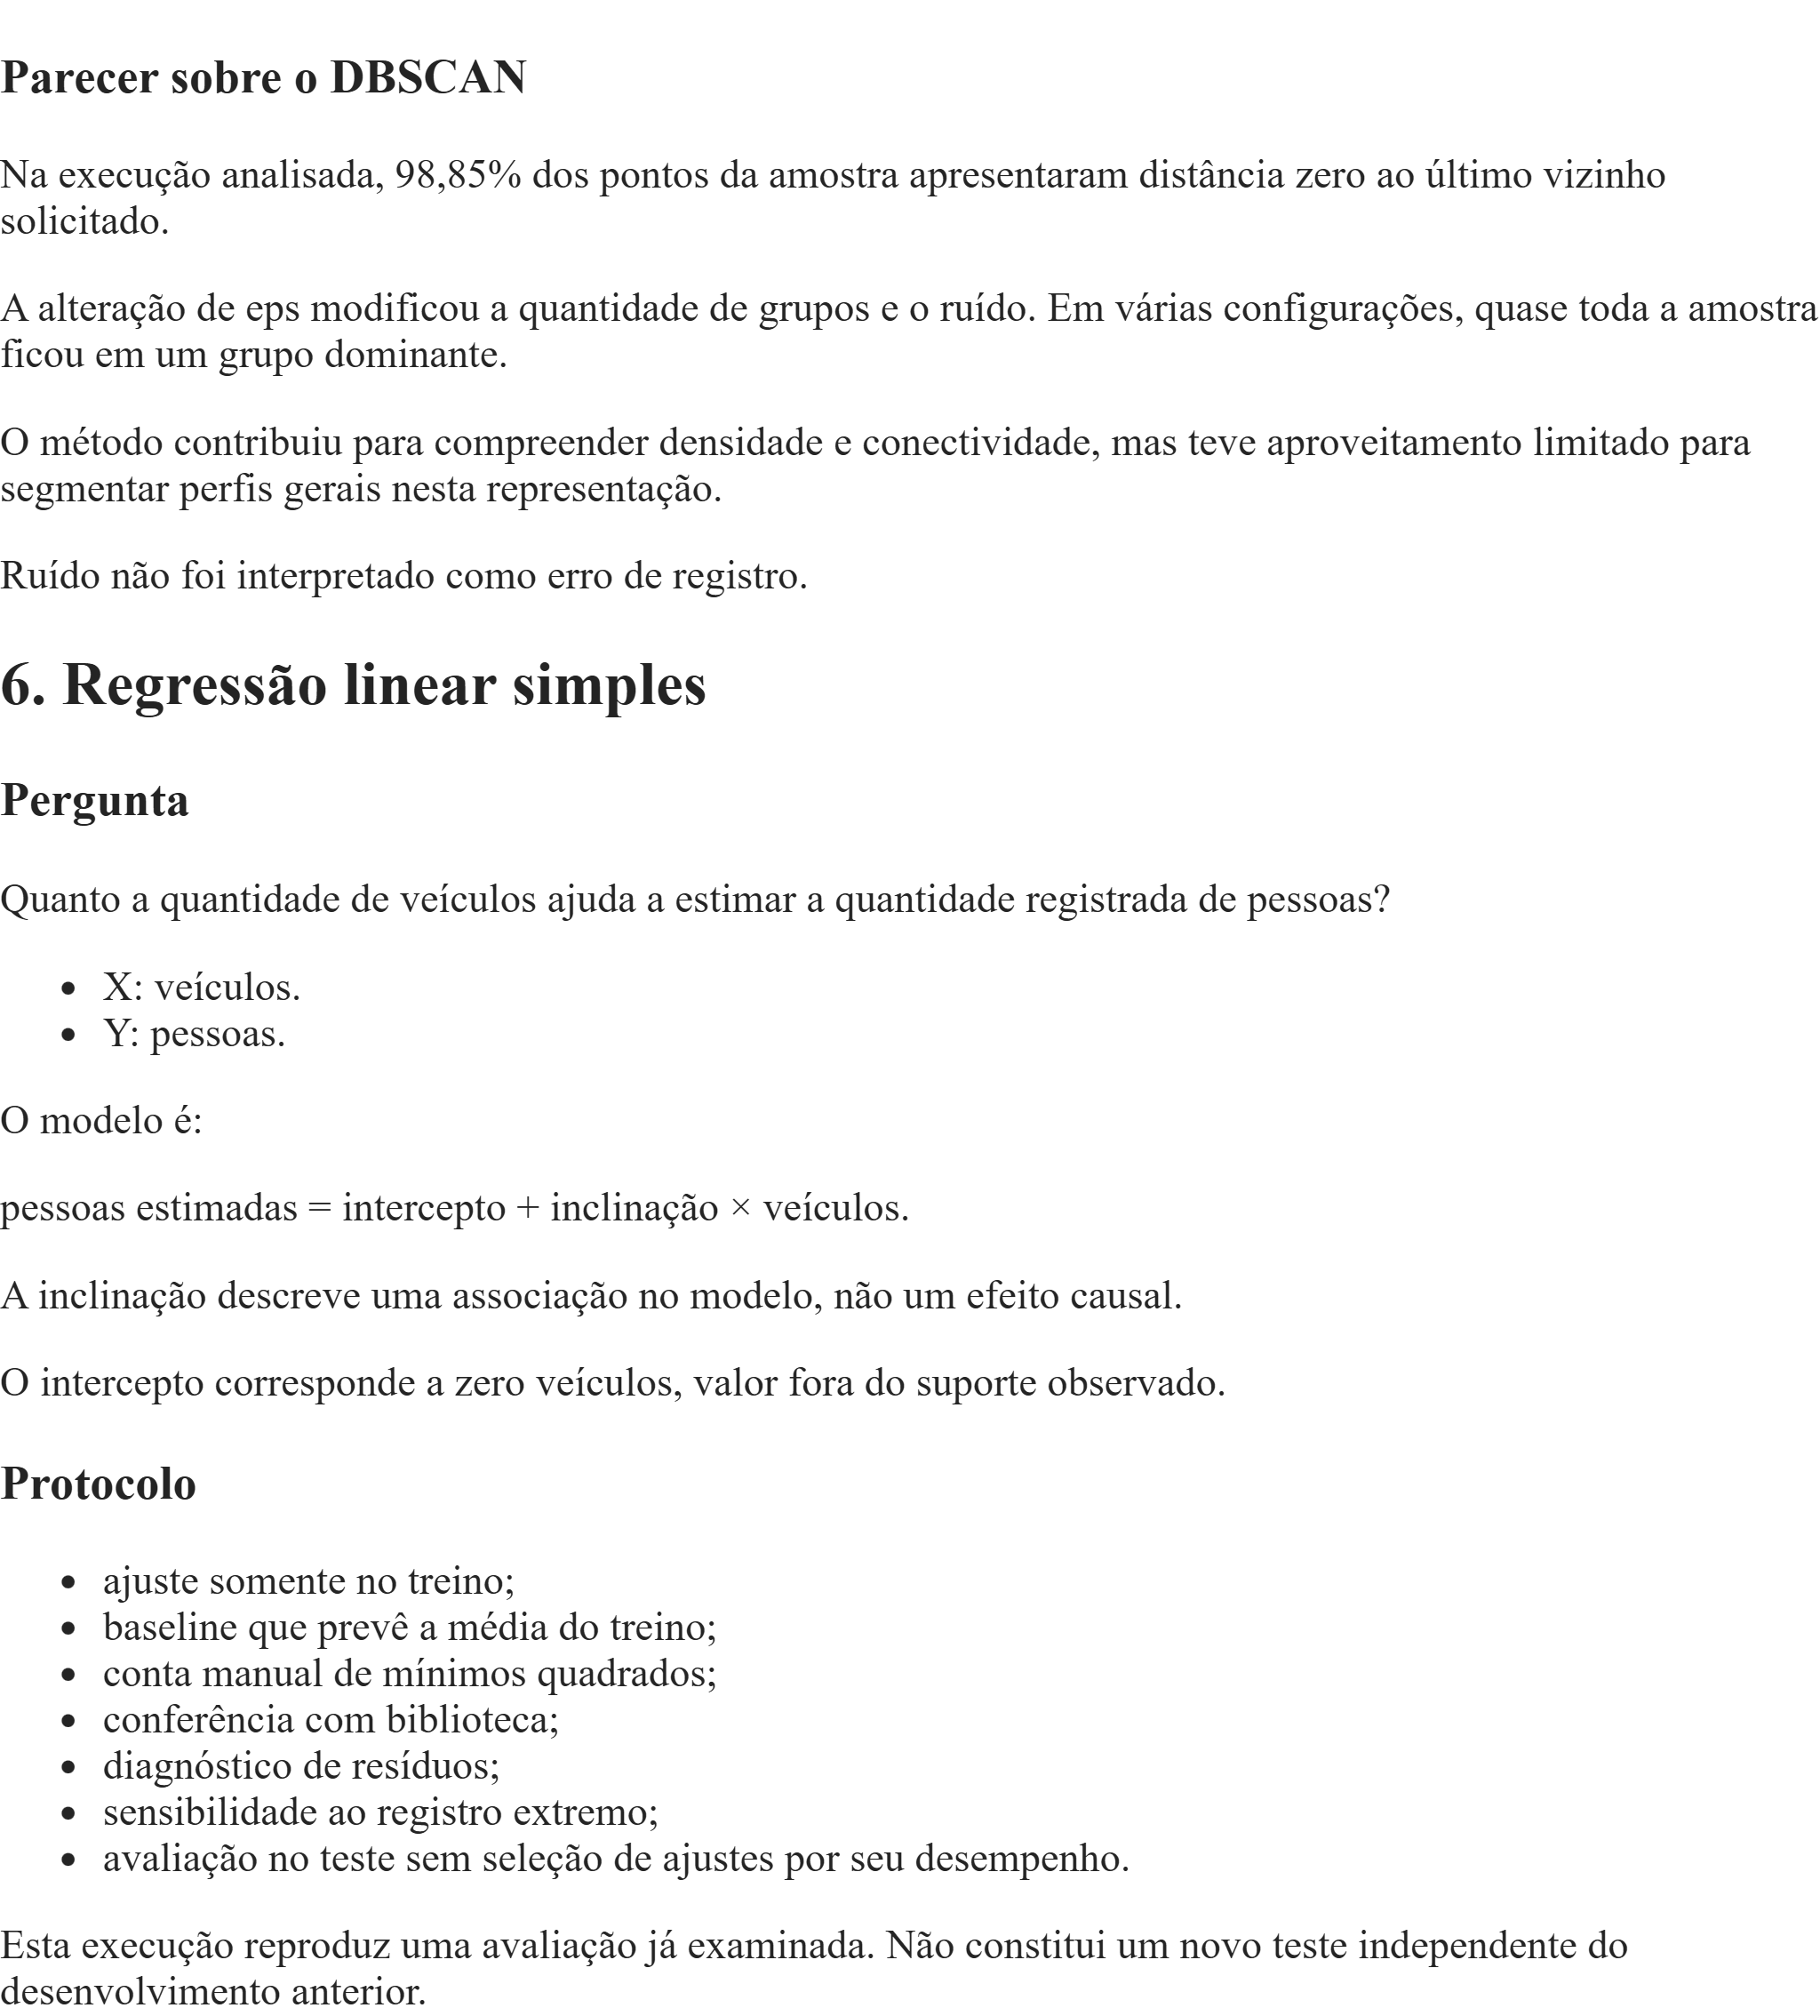

,coeficiente,manual,biblioteca
0,Intercepto,1.044125,1.044125
1,Inclinação,0.775054,0.775054


,componente,valor
0,SQT,262762.1557
1,SQR,39989.7479
2,SQE,222772.4078


,MAE,MSE,RMSE,R2,particao,modelo
0,1.1635,5.1755,2.2750,0.0000,Treino,Baseline da média
1,0.9064,4.3879,2.0947,0.1522,Treino,Regressão linear
2,1.1587,4.8757,2.2081,-0.0000,Teste,Baseline da média
3,0.9089,4.0652,2.0162,0.1662,Teste,Regressão linear


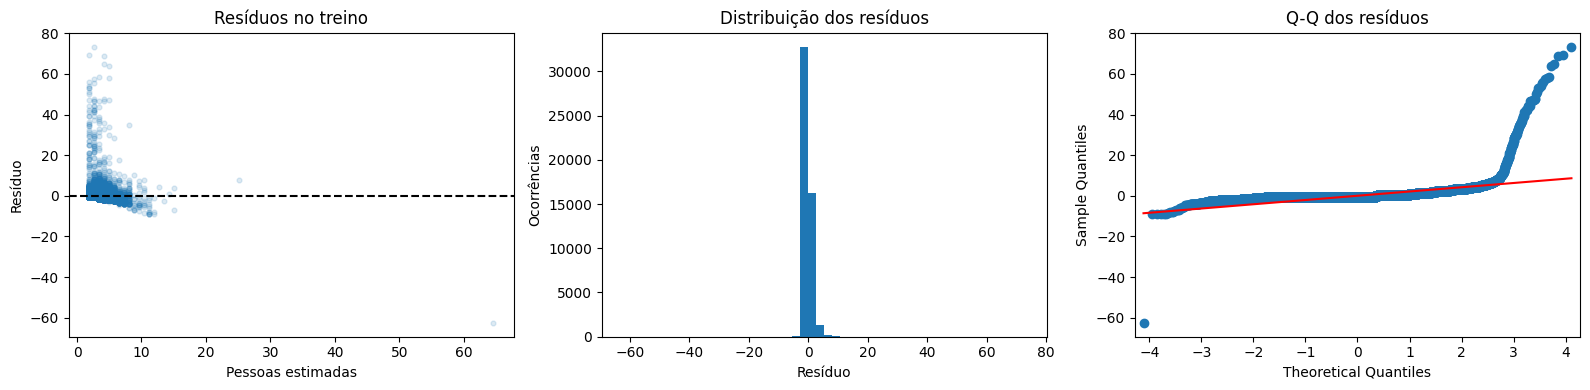

                            OLS Regression Results                            
Dep. Variable:                pessoas   R-squared:                       0.152
Model:                            OLS   Adj. R-squared:                  0.152
Method:                 Least Squares   F-statistic:                     9113.
Date:                Thu, 12 Nov 2026   Prob (F-statistic):               0.00
Time:                        01:34:56   Log-Likelihood:            -1.0958e+05
No. Observations:               50770   AIC:                         2.192e+05
Df Residuals:                   50768   BIC:                         2.192e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.0441      0.019     55.811      0.0

,ajuste,intercepto,inclinacao
0,Completo,1.044125,0.775054
1,Sem ID 707992,0.879057,0.858283


Diferença absoluta média das previsões nos registros comuns: 0.05455995190496569
Teste fora do intervalo de X do treino: 0
Previsões negativas: 0


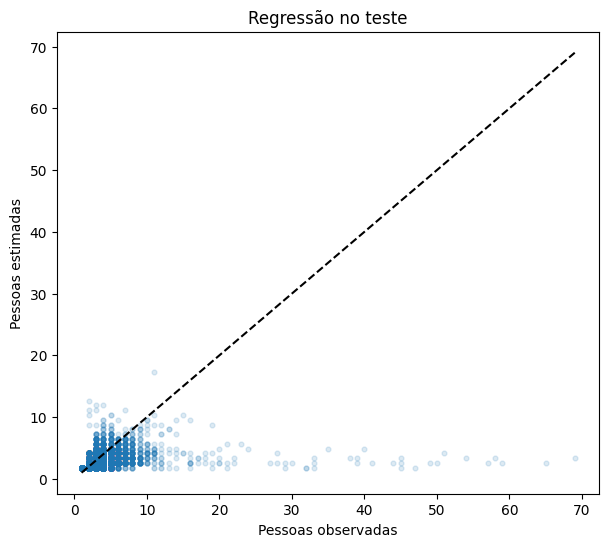

In [8]:
# Dados da regressão, nas unidades originais.
X_reg_treino = treino[["veiculos"]].copy()
y_reg_treino = treino["pessoas"].astype(float).copy()

X_reg_teste = teste[["veiculos"]].copy()
y_reg_teste = teste["pessoas"].astype(float).copy()

assert X_reg_treino.index.equals(y_reg_treino.index)
assert X_reg_teste.index.equals(y_reg_teste.index)

# Mínimos quadrados calculados manualmente.
x = X_reg_treino["veiculos"].to_numpy(dtype=float)
y = y_reg_treino.to_numpy(dtype=float)

dx = x - x.mean()
dy = y - y.mean()

assert np.sum(dx ** 2) > 0

b1_manual = np.sum(dx * dy) / np.sum(dx ** 2)
b0_manual = y.mean() - b1_manual * x.mean()

# Ajuste pela biblioteca.
regressao = LinearRegression().fit(
    X_reg_treino, y_reg_treino
)

assert np.isclose(b0_manual, regressao.intercept_)
assert np.isclose(b1_manual, regressao.coef_[0])

display(pd.DataFrame({
    "coeficiente": ["Intercepto", "Inclinação"],
    "manual": [b0_manual, b1_manual],
    "biblioteca": [regressao.intercept_, regressao.coef_[0]]
}).round(6))

# Baseline ajustado somente no treino.
baseline_reg = DummyRegressor(strategy="mean").fit(
    X_reg_treino, y_reg_treino
)

pred_treino = regressao.predict(X_reg_treino)
residuos_treino = y - pred_treino

# Decomposição no treino, com intercepto.
SQT = np.sum((y - y.mean()) ** 2)
SQE = np.sum(residuos_treino ** 2)
SQR = np.sum((pred_treino - y.mean()) ** 2)

assert np.isclose(SQT, SQR + SQE)

display(pd.DataFrame({
    "componente": ["SQT", "SQR", "SQE"],
    "valor": [SQT, SQR, SQE]
}).round(4))


def metricas_regressao(real, previsto):
    mse = mean_squared_error(real, previsto)

    return {
        "MAE": mean_absolute_error(real, previsto),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(real, previsto)
    }


# Métricas de treino e teste para os modelos já definidos.
resultados_reg = []

for particao, X_parte, y_parte in [
    ("Treino", X_reg_treino, y_reg_treino),
    ("Teste", X_reg_teste, y_reg_teste)
]:
    for nome, modelo in [
        ("Baseline da média", baseline_reg),
        ("Regressão linear", regressao)
    ]:
        resultado = metricas_regressao(
            y_parte, modelo.predict(X_parte)
        )
        resultado["particao"] = particao
        resultado["modelo"] = nome
        resultados_reg.append(resultado)

tabela_regressao = pd.DataFrame(resultados_reg)
display(tabela_regressao.round(4))

# Diagnóstico dos resíduos no treino.
fig, eixos = plt.subplots(1, 3, figsize=(16, 4))

eixos[0].scatter(
    pred_treino, residuos_treino, alpha=0.15, s=12
)
eixos[0].axhline(0, color="black", linestyle="--")
eixos[0].set_xlabel("Pessoas estimadas")
eixos[0].set_ylabel("Resíduo")
eixos[0].set_title("Resíduos no treino")

eixos[1].hist(residuos_treino, bins=50)
eixos[1].set_xlabel("Resíduo")
eixos[1].set_ylabel("Ocorrências")
eixos[1].set_title("Distribuição dos resíduos")

sm.qqplot(residuos_treino, line="s", ax=eixos[2])
eixos[2].set_title("Q-Q dos resíduos")

plt.tight_layout()
plt.show()

# Resumo estatístico: inferência sujeita aos pressupostos.
ajuste_ols = sm.OLS(
    y_reg_treino,
    sm.add_constant(X_reg_treino, has_constant="add")
).fit()

print(ajuste_ols.summary())

# Sensibilidade sem alterar a regressão principal.
X_comuns = treino_sem_extremo[["veiculos"]]
y_comuns = treino_sem_extremo["pessoas"].astype(float)

regressao_sem_extremo = LinearRegression().fit(
    X_comuns, y_comuns
)

display(pd.DataFrame({
    "ajuste": ["Completo", "Sem ID 707992"],
    "intercepto": [
        regressao.intercept_,
        regressao_sem_extremo.intercept_
    ],
    "inclinacao": [
        regressao.coef_[0],
        regressao_sem_extremo.coef_[0]
    ]
}).round(6))

print(
    "Diferença absoluta média das previsões nos registros comuns:",
    np.mean(np.abs(
        regressao.predict(X_comuns)
        - regressao_sem_extremo.predict(X_comuns)
    ))
)

# Verificações e gráfico no teste.
pred_teste = regressao.predict(X_reg_teste)

fora_intervalo = (
    X_reg_teste["veiculos"].lt(X_reg_treino["veiculos"].min())
    | X_reg_teste["veiculos"].gt(X_reg_treino["veiculos"].max())
)

print("Teste fora do intervalo de X do treino:", int(fora_intervalo.sum()))
print("Previsões negativas:", int(np.sum(pred_teste < 0)))

plt.figure(figsize=(7, 6))
plt.scatter(y_reg_teste, pred_teste, alpha=0.15, s=12)

limites = [
    min(float(y_reg_teste.min()), float(pred_teste.min())),
    max(float(y_reg_teste.max()), float(pred_teste.max()))
]

plt.plot(limites, limites, color="black", linestyle="--")
plt.xlabel("Pessoas observadas")
plt.ylabel("Pessoas estimadas")
plt.title("Regressão no teste")
plt.show()

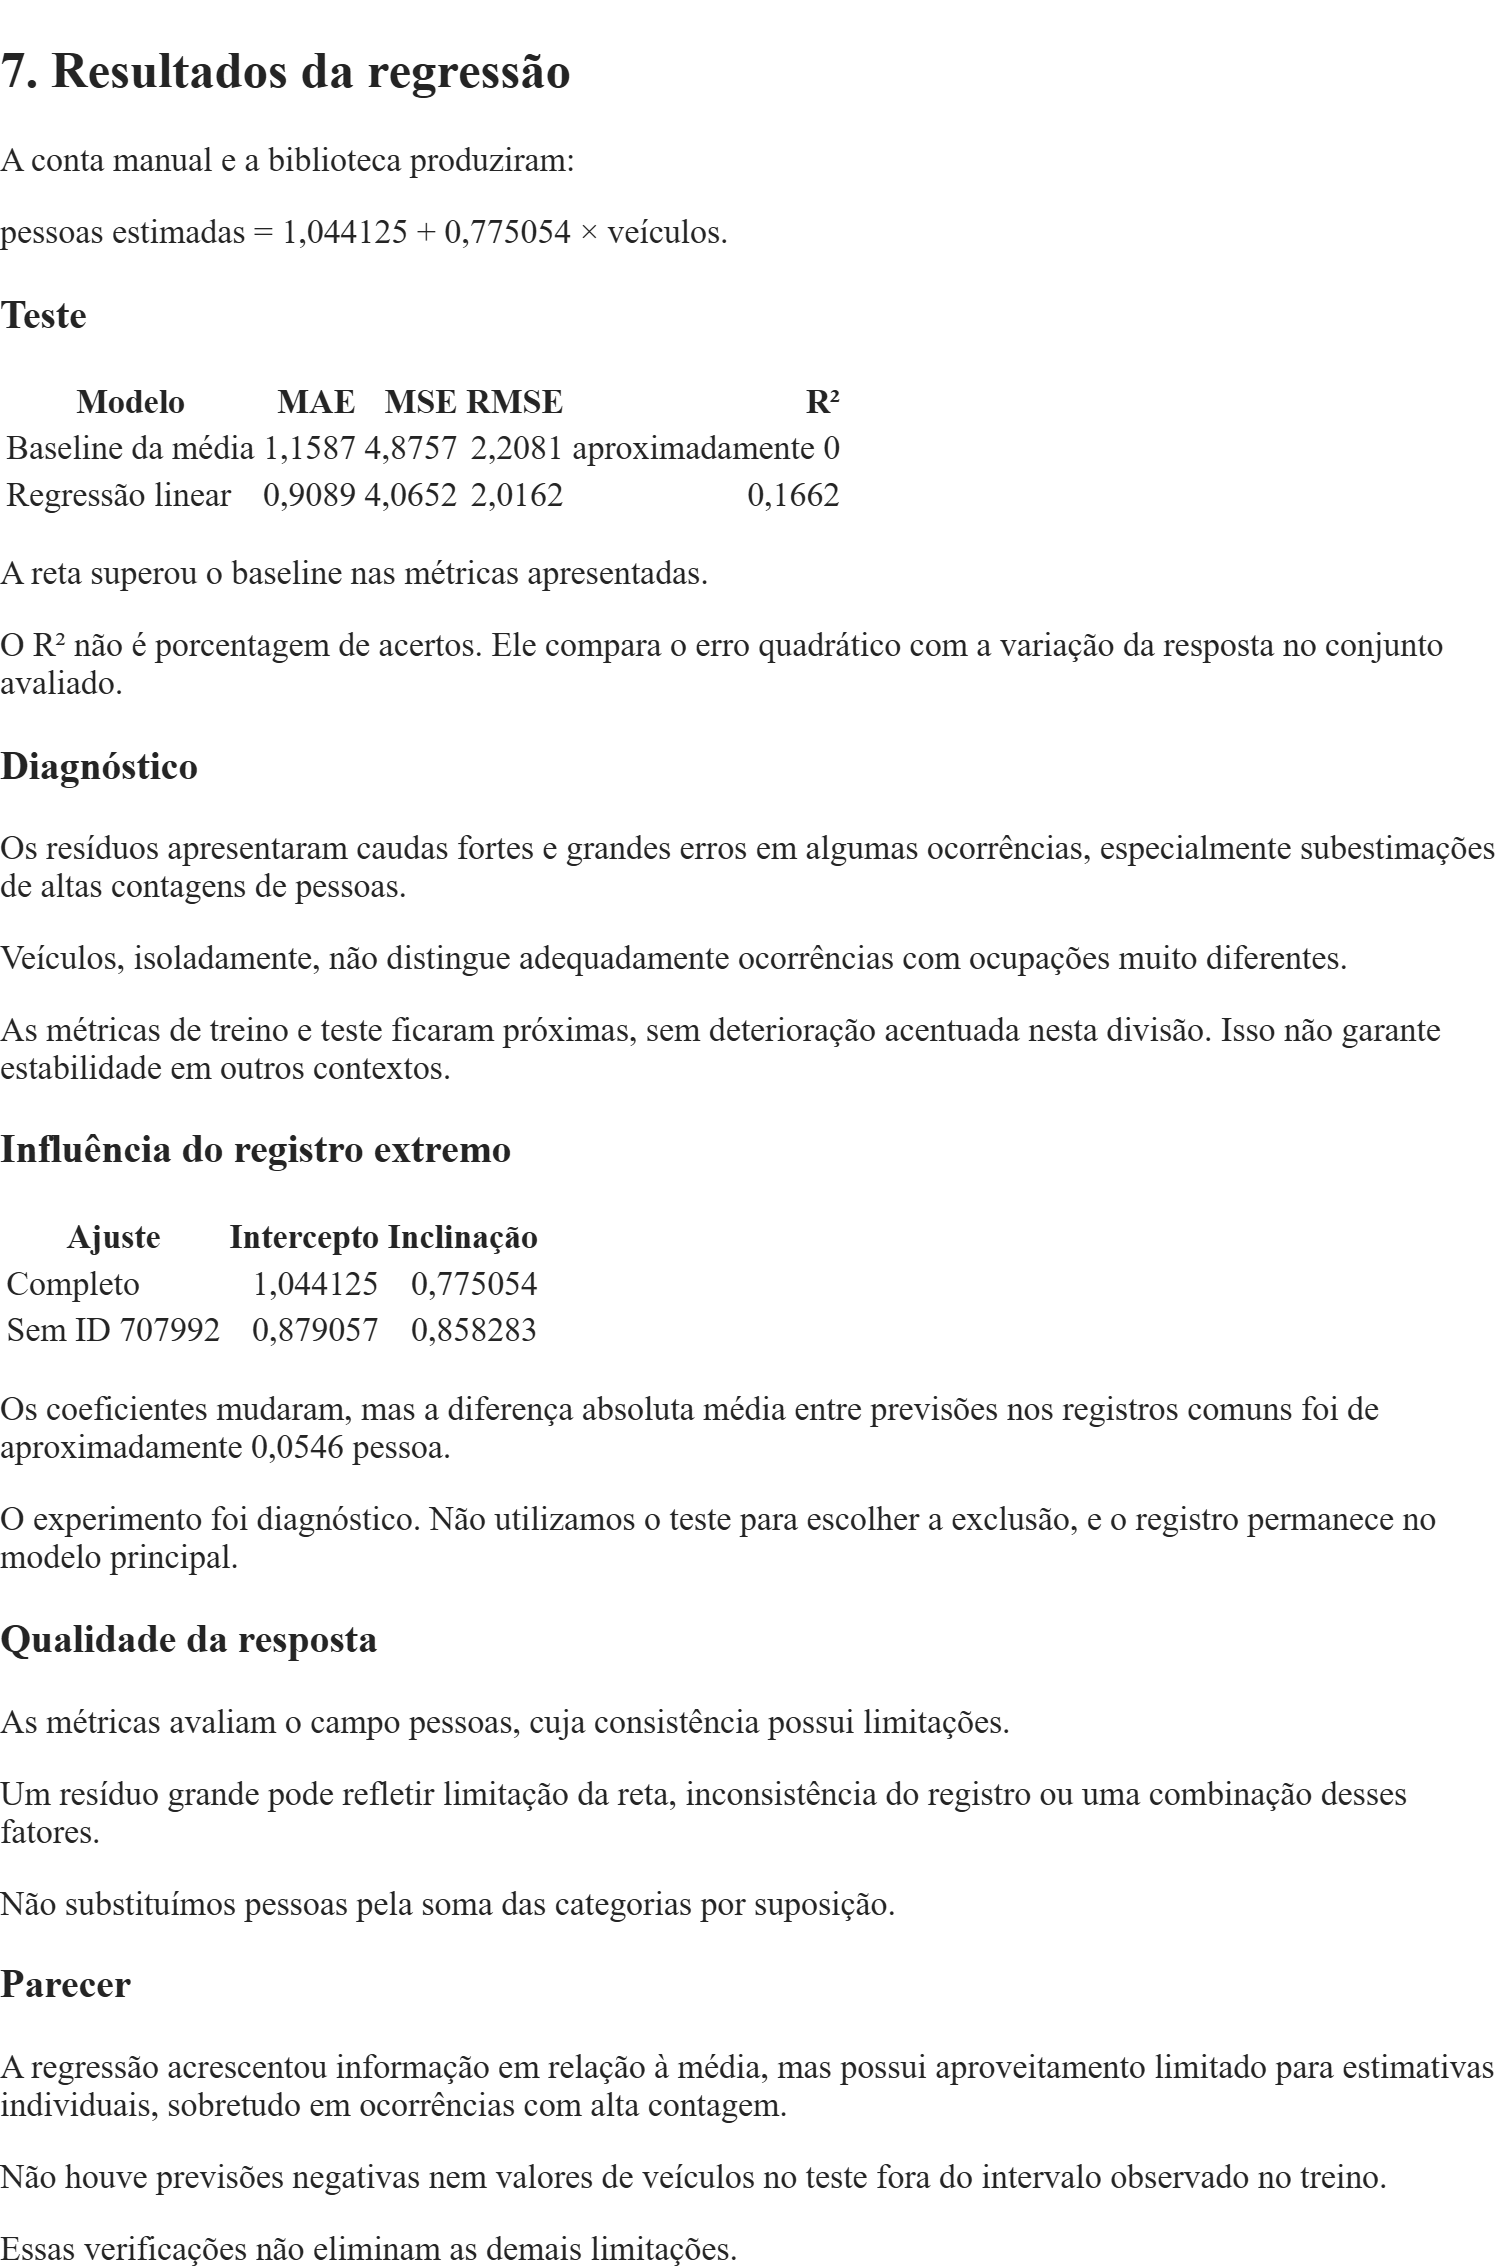

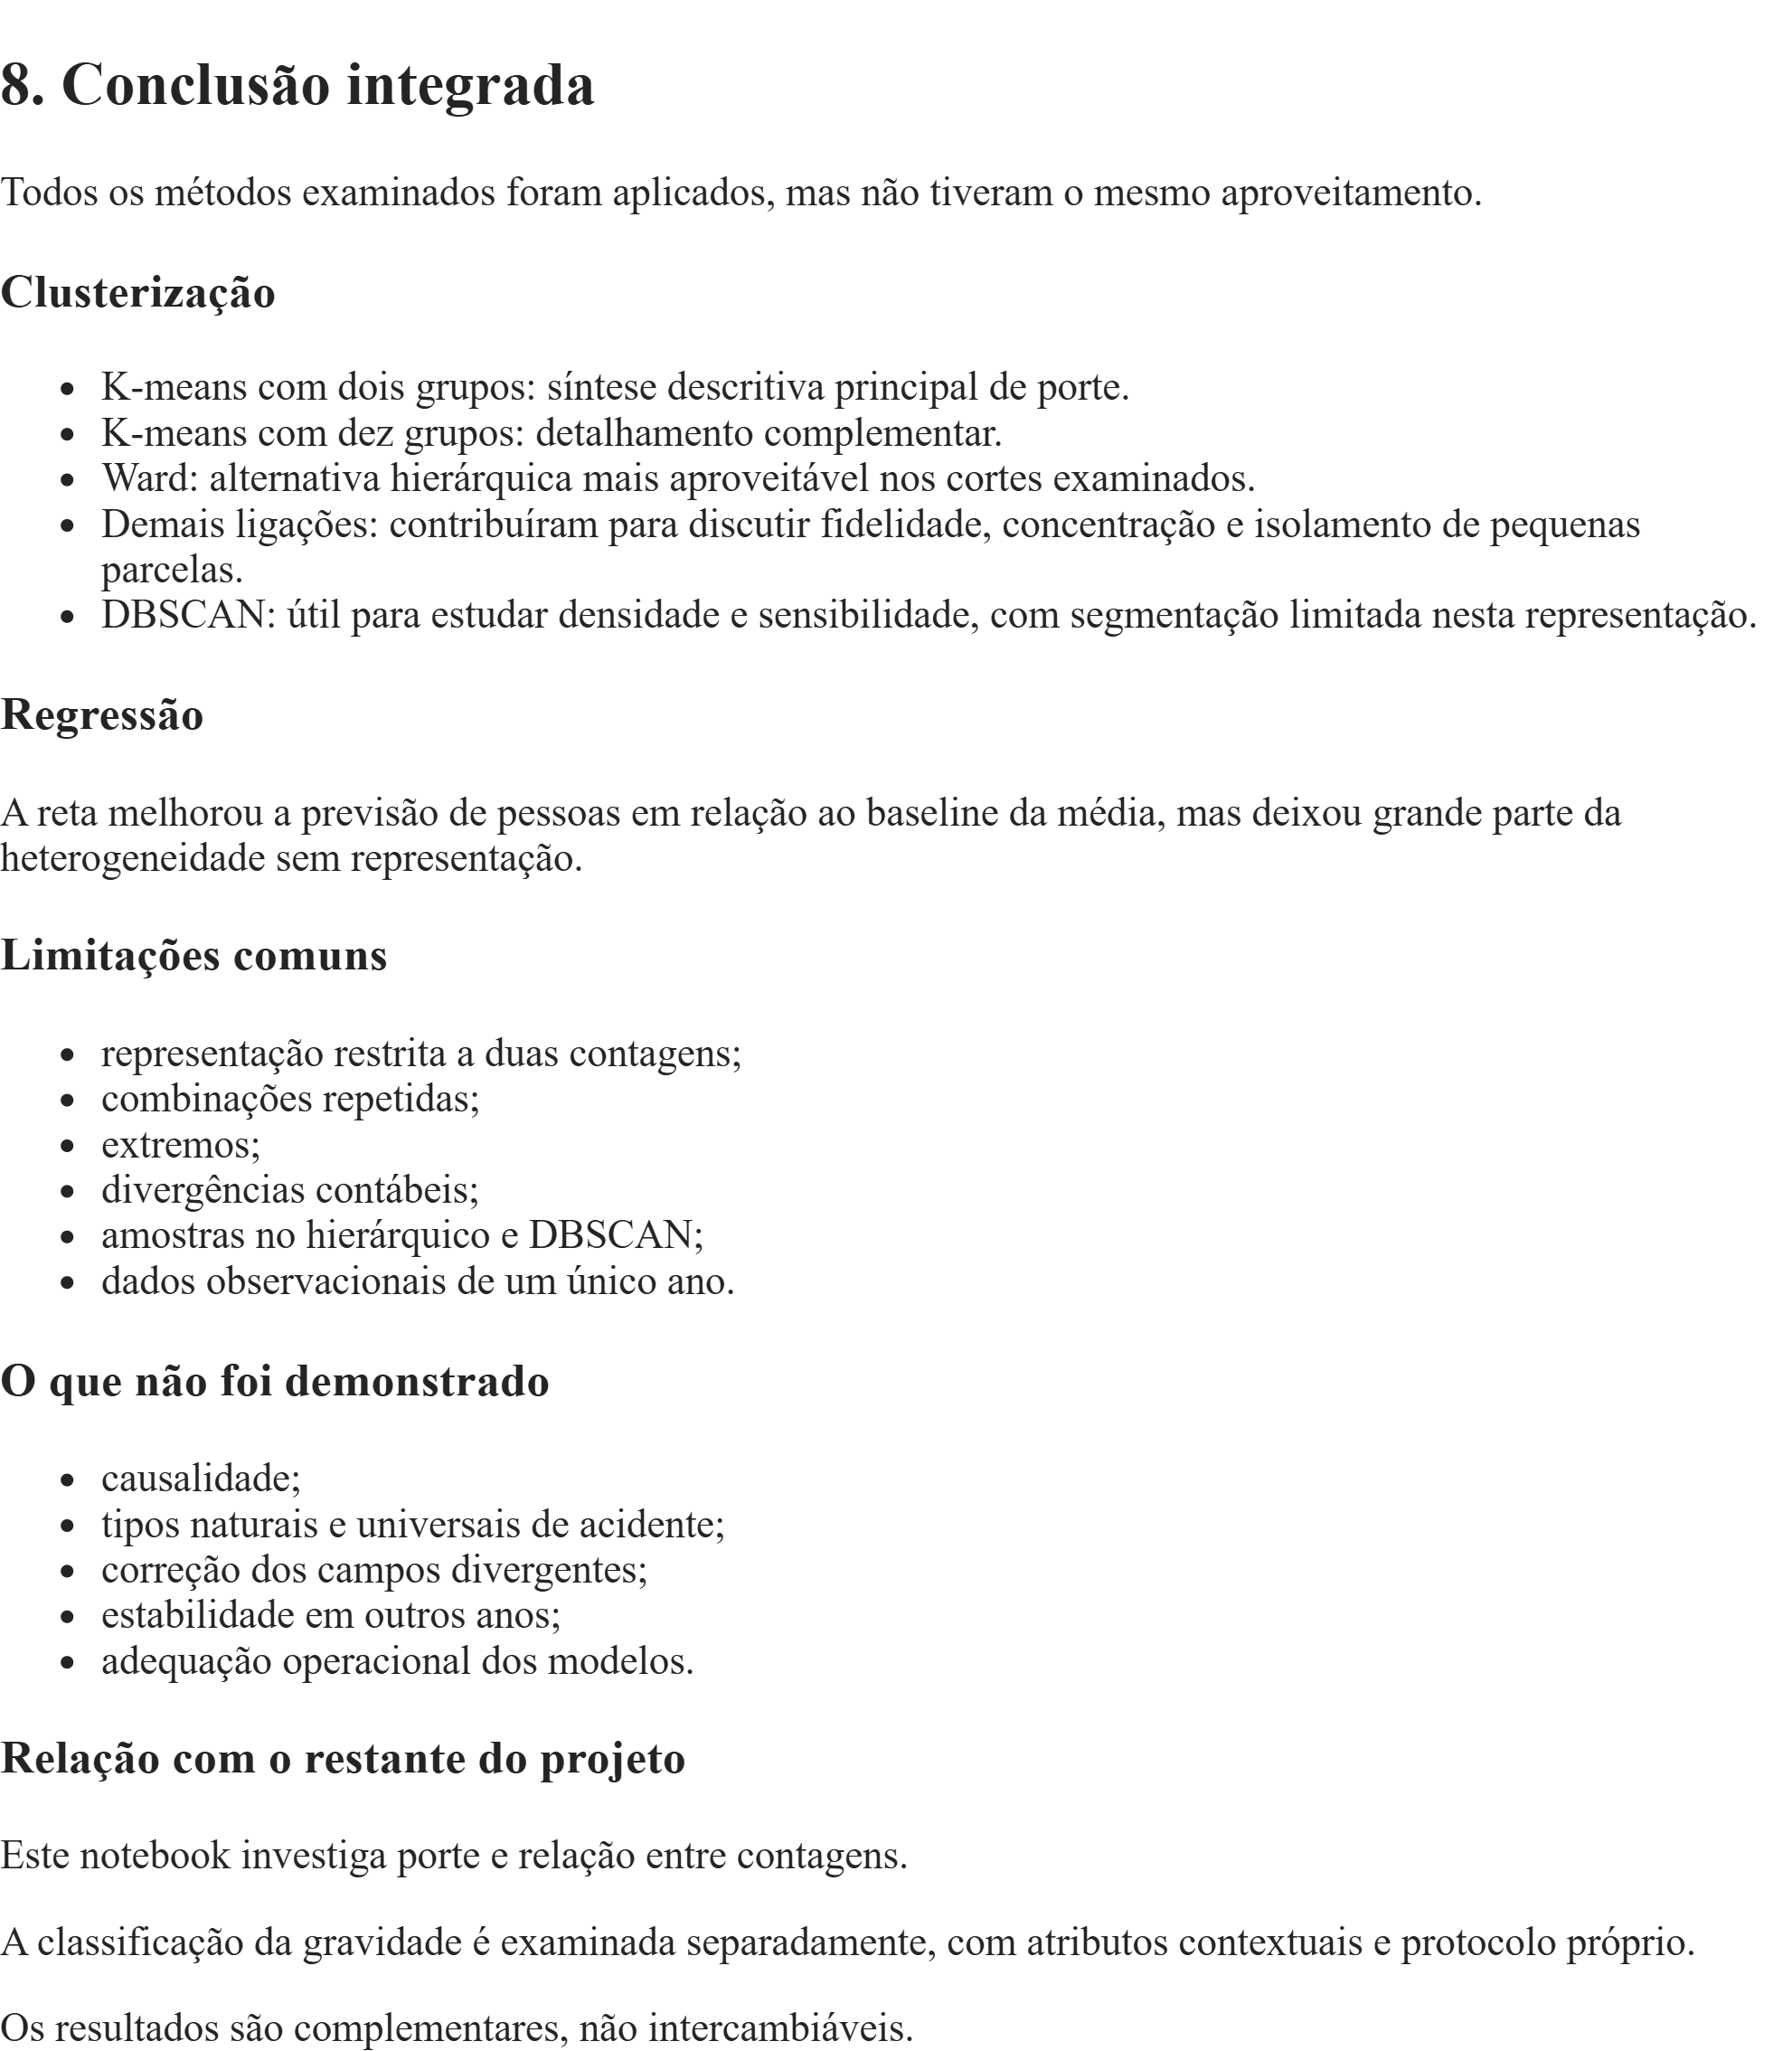

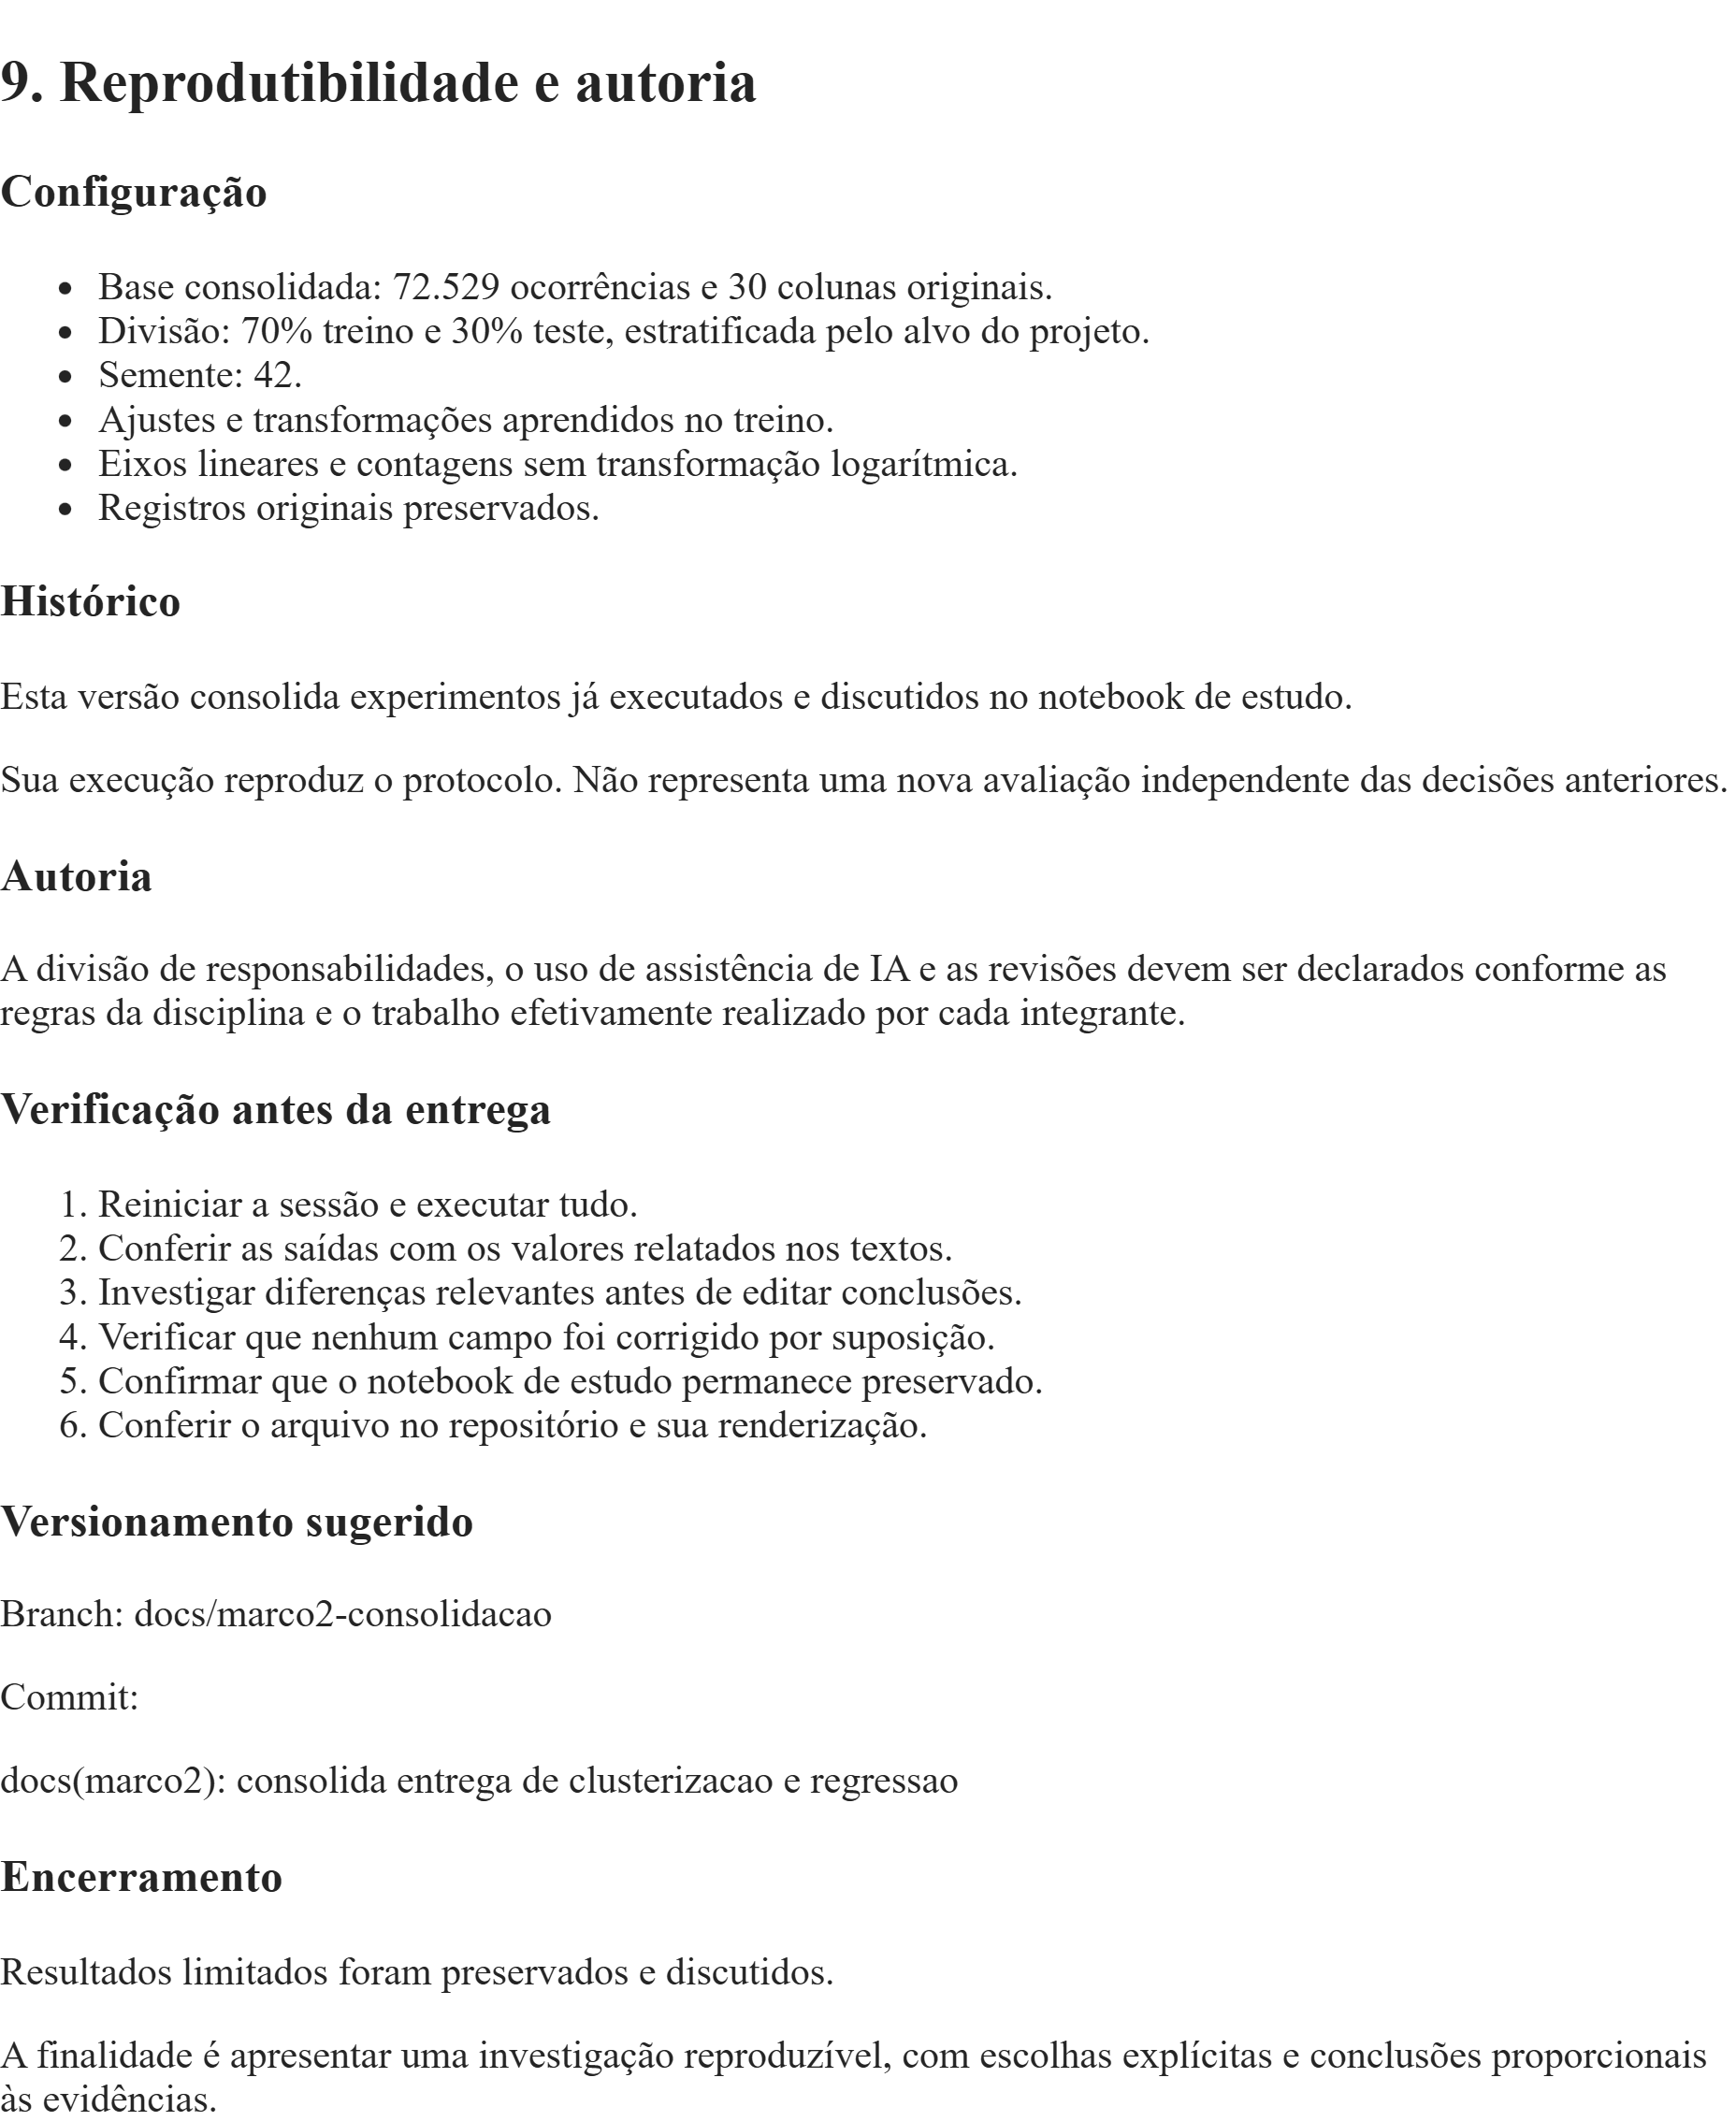